<a href="https://colab.research.google.com/github/jose-esquivel-dev/Analitica_de_Datos/blob/main/U3/Practica_2/AD_U3_Practica2_Equipo3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

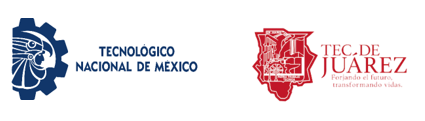

#**INSTITUTO TECNOLOGICO DE CIUDAD JUAREZ**
**Ciencia y analítica de datos**

**Integrantes del equipo:**
*   Delgado Ramírez María Fernanda
*   Esquivel Torres Jose Enrique
*   Llanas Hernández Mia


## **MODELOS DE APRENDIZAJE**
 **UNIDAD 4**

Perceptrón simple y multicapa


## Aprendizaje profundo
## Redes neuronales profundas completamente conectadas

- Objetivo

El propósito de esta parte de la actividad es aplicar los conocimientos sobre redes completamente conectadas mediante la implementación de una red multicapa para el dataset [ASL de Kaggle, American Sign Language](https://www.kaggle.com/datasets/grassknoted/asl-alphabet). Se proporcionó una solución completa con NumPy para el dataset MNIST y se recomienda desarrollar la solución propia. En este notebook se implementa además un perceptrón simple con el fin de comparar ambas arquitecturas.

- Instrucciones

    Cargar y preprocesar los datos: se proporciona un código inicial para cargar los datos. Es necesario comprender su funcionamiento.

    Revisar el notebook de MNIST, de forma opcional: antes de iniciar la actividad se puede revisar el ejemplo de MNIST para recordar cómo construir una red completamente conectada con NumPy.

    Comenzar desde cero: aunque la solución de MNIST puede consultarse en cualquier momento, se recomienda implementar la red para el dataset ASL de forma independiente. Esto refuerza la comprensión de la arquitectura y de las matemáticas involucradas.

    Implementar el avance y el retroceso: escribir el código de los pasos de avance y retroceso, considerando las características del dataset ASL.

    Diseñar la red: crear la arquitectura de la red completamente conectada para el dataset ASL y elegir con criterio el número de capas ocultas, el número de neuronas y los hiperparámetros.

    Entrenar el modelo: ejecutar el ciclo de entrenamiento y registrar métricas de desempeño como el costo y la exactitud.

    Analizar y documentar: usar celdas de texto para documentar en detalle las decisiones de arquitectura e hiperparámetros, apoyándose en figuras, ecuaciones y métricas que justifiquen esas decisiones, y discutir el desempeño del modelo.

--------------------------------------------------------------------------
# **INTRODUCCIÓN**

El lenguaje de señas estadounidense, conocido como ASL por sus siglas en inglés, es un sistema visual y gestual utilizado principalmente por personas sordas o con dificultades auditivas. Combina señas con las manos, expresiones faciales, movimientos corporales y posición de las manos para transmitir significados, ideas y emociones. Sus orígenes se remontan al siglo XIX, cuando se fundó en 1817 la primera escuela para sordos de Estados Unidos, conocida como "Hartford School for the Deaf".

Actualmente el ASL se reconoce como una lengua con gramática y estructura propias. Es utilizado por la comunidad sorda en Estados Unidos y en otras partes del mundo, lo que promueve la identidad cultural de las personas sordas y su inclusión en la sociedad.

En este notebook se implementan dos modelos para el dataset ASL de Kaggle: un perceptrón simple y un perceptrón multicapa completamente conectado. Al final se comparan sus resultados.

--------------------------------------------------------------------------

## **Importación de las librerías necesarias**

En esta celda se cargan las herramientas que se usarán a lo largo del notebook. Cada una cumple una función distinta:

- **numpy:** permite trabajar con arreglos y matrices de números, que es la base de todos los cálculos de la red neuronal.
- **string:** ofrece utilidades para manejar texto, que servirán para asignar las letras del alfabeto a las etiquetas de cada seña.
- **pandas:** permite leer los archivos CSV donde viene el dataset y ordenarlos en tablas.
- **matplotlib:** sirve para crear gráficas e imágenes, por ejemplo para ver cómo luce cada seña.
- **cv2 (OpenCV):** es una librería para procesar imágenes.
- **os:** permite manejar rutas de carpetas y archivos del sistema.

Además, la celda activa dos configuraciones del notebook. La primera recarga los módulos automáticamente cuando se modifican, y la segunda hace que las gráficas se muestren directamente debajo de cada celda. También se importa `drive` de Google Colab, que se usará en la siguiente celda para conectar el notebook con la carpeta donde se guardan los datos.

In [ ]:
import numpy as np #manejo de arreglos, matrices
import string #utiles para etiquetas de texto
import pandas as pd #lectura y manipulacion de CSV
import matplotlib.pyplot as plt #graficar
import cv2 as cv #procesamiento de imagenes
import os #manejo de rutas de archivos

#muestra graficas directamente en el notebook
%matplotlib inline

from google.colab import drive
import sys

In [ ]:
#We want to get the path where our dataset is stored
drive.mount('/content/drive')

!ls '/content/drive/My Drive/Colab Notebooks/Analisis'

Mounted at /content/drive
 Actividad2_DelgadoRamírez.ipynb
'Actividad Serie_De_Tiempo (1).ipynb'
 AD_U2_Práctica1_DelgadoRamírez.ipynb
 AD_U2_Practica1_Equipo3.ipynb
 AD_U2_Practica2_Equipo3.ipynb
 AD_U2_Práctica3_EjemploModeloRegresionLineal_DelgadoRamírez.ipynb
 AD_U2_Practica3_Equipo3.ipynb
 AD_U2_Práctica4_DelgadoRamírez.ipynb
 AD_U2_Practica4_Equipo3.ipynb
 AD_U3_Práctica2_DelgadoRamírez.ipynb
 AD_U3_Practica2_Equipo_v2.ipynb
 AD_U3_Práctica3_DelgadoRamírez.ipynb
 AD_U3_Práctica4_DelgadoRamírez.ipynb
 arboles_de_decision.ipynb
 asl_data
 bigMartSales.csv
'Copia de Actividad Serie_De_Tiempo (1).ipynb'
 credit_risk_dataset.csv
 data.csv
 dictionary.txt
 EjemploModeloRegresionLineal.ipynb
'EJEMPLO RED NEURONAL(2).ipynb'
 events.csv
 Forbes_2000_top_company.csv
 geoplaces2.csv
 ginf.csv
 Proyecto_AD.ipynb
 rating_final.csv
'SVD - Sistema Recomedacion.ipynb'


### **Carga de los datos**

En esta celda se define la ruta de la carpeta donde está guardado el dataset y se leen los dos archivos CSV que contiene. El primero corresponde al conjunto de entrenamiento, que es el que la red usará para aprender, y se guarda en la variable `train_df`. El segundo corresponde al conjunto de validación, que servirá para comprobar qué tan bien aprendió, y se guarda en la variable `valid_df`. Ambos se almacenan como tablas de pandas.

In [ ]:
#This is the path were we have the data
DATA_PATH = '/content/drive/My Drive/Colab Notebooks/Analisis/asl_data'
#The folder has 2 files, one has the data for the training set and the other one has data for the validation set, let's store them into variables train_df and valid_df
train_df = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_train.csv'))
valid_df = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_valid.csv'))

### **Vista previa del conjunto de entrenamiento**

Aquí se muestran las primeras cinco filas de la tabla de entrenamiento para conocer cómo vienen organizados los datos. Cada fila representa una imagen de una seña. La primera columna, llamada `label`, indica la letra que corresponde a la imagen, representada con un número. Las demás columnas contienen el valor de cada pixel de la imagen, que va de 0 a 255 según su nivel de gris. Las imágenes miden 28 por 28 pixeles, por lo que cada una ocupa 784 columnas.

In [ ]:
#Now we want to see the first 5 rows of the train set
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,12,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


### **Vista previa del conjunto de validación**

Se repite la vista previa con la tabla de validación. Tiene la misma estructura que la de entrenamiento, con la columna `label` y las columnas de pixeles, lo que confirma que ambos conjuntos se pueden procesar de la misma manera.

In [ ]:
#Now we want to see the first 5 rows of the validation set
valid_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,6,149,149,150,150,150,151,151,150,151,...,138,148,127,89,82,96,106,112,120,107
1,5,126,128,131,132,133,134,135,135,136,...,47,104,194,183,186,184,184,184,182,180
2,9,85,88,92,96,105,123,135,143,147,...,68,166,242,227,230,227,226,225,224,222
3,0,203,205,207,206,207,209,210,209,210,...,154,248,247,248,253,236,230,240,253,255
4,3,188,191,193,195,199,201,202,203,203,...,26,40,64,48,29,46,49,46,46,53


## **Importación de las imágenes**

### **Separación de las etiquetas y las imágenes**

En esta celda se divide cada tabla en dos partes. La primera son las etiquetas, es decir, la letra que representa cada seña, y se guardan en `y_train` para entrenamiento y en `y_val` para validación. Estas son las respuestas correctas que la red intentará predecir. Una vez guardadas, la columna `label` se elimina de las tablas.

La segunda parte son los pixeles de cada imagen, que quedan en `x_train` y `x_val`. Estos son los datos de entrada que recibirá la red. Se convierten a números decimales de tipo `float32`, un formato adecuado para los cálculos de la red neuronal.

In [ ]:
#Now we will get the output which we will store in the variable y_train and y_valid, the output is going to be the column "label" from each df.
y_train = np.array(train_df['label'])
y_val = np.array(valid_df['label'])

del train_df['label']
del valid_df['label']

x_train = train_df.values.astype(np.float32)
x_val = valid_df.values.astype(np.float32)

### **Verificación del tamaño de las etiquetas**

Esta celda muestra la cantidad de elementos que tiene `y_val`. El resultado indica que el conjunto de validación contiene 7172 etiquetas, una por cada imagen. Esta cifra es útil porque más adelante este conjunto se dividirá en dos partes.

In [ ]:
#We see that the output data for the validation set has 7172 rows.
y_val.shape

(7172,)

PROCESAMIENTO

### **Función para dividir validación y prueba**

En esta celda se define la función `split_val_test`, que toma el conjunto de validación original y lo divide en dos partes: validación, que sirve para ajustar el modelo, y prueba, que sirve para evaluar el modelo final con datos que nunca vio durante el ajuste.

La función sigue cuatro pasos. Primero une los pixeles y las etiquetas en una sola matriz para que cada imagen conserve su respuesta correcta. Después mezcla las filas de manera aleatoria, lo cual evita que los datos queden ordenados por letra y que alguno de los dos conjuntos reciba solo ciertas clases. Luego calcula el punto de corte según el porcentaje indicado, que por defecto es 0.5, es decir, la mitad para cada conjunto. Finalmente separa de nuevo los pixeles de las etiquetas y devuelve los cuatro grupos: `x_val`, `y_val`, `x_test` y `y_test`.

In [ ]:
#This is the function split_val_test to split the data from the validation set into validation and test sets.
def split_val_test(x, y, pct=0.5, shuffle=True):
    '''

    TOMA EL CONJUNTO X_VAL Y LO SEPARA EN :
    - VALIDACION (para ajustar el modelo)
    - PRUEBA (para evaluar el modelo final)

    Divide a validation dataset into two subsets: validation and test.

    param x: array or list of features from the dataset (Caracteristicas (IMAGENES))
    param y: array or list of labels from the dataset (ETIQUETAS (CLASES))
    param pct: PORCENTAJE PARA EL CONJUNTO DE VALIDACION
    param shuffle: PARA MEZCLAR LOS DATOS ANTES

    return: two sets (x_val, y_val) for validation, and (x_test, y_test) for testing
    '''

    # Combine x and y into one structure for easy splitting
    # UNE LAS ENTRADAS X Y ETIQUETAS Y EN UNA SOLA MATRIZ
    data = np.column_stack((x, y))

    # Shuffle the data if required
    #EL MEZCLAR ALEATORIAMENTE LOS DATOS EVITA SESGOS COMO: datos ordenados por clase o entrenamiento poce generalizable
    if shuffle:
      np.random.shuffle(data)

    # Determine the index for splitting the data
    #divide en 2 el conjunto (mitad para validacion y mitadl para prueba)
    split_index = int(len(data) * pct)

    # Split the data into validation and test sets
    val_data = data[:split_index]   # The first pct data points are fot the val set
    test_data = data[split_index:]  # The rest is for the test set

    # Separate features (x) and labels (y) for the validation and test sets
    x_val, y_val = val_data[:, :-1], val_data[:, -1].astype(int)
    x_test, y_test = test_data[:, :-1], test_data[:, -1].astype(int)

    return x_val, y_val, x_test, y_test

### **Aplicación de la división**

Aquí se llama a la función anterior con el conjunto de validación original. El resultado reemplaza a `x_val` y `y_val` con la mitad de los datos y crea `x_test` y `y_test` con la otra mitad.

In [ ]:
# Split the validation set into validation and test sets
x_val, y_val, x_test, y_test = split_val_test(x_val, y_val)

### **Verificación de la división**

Esta celda imprime las dimensiones de los dos conjuntos resultantes. Cada uno contiene 3586 imágenes de 784 pixeles junto con sus 3586 etiquetas. Como las 7172 imágenes originales se repartieron en partes iguales, se confirma que la división se realizó correctamente.

In [ ]:
# Output the results to confirm that the function splitted correctly
print("Validation set (x_val_split, y_val_split):")
print(x_val.shape, y_val.shape)

print("\nTest set (x_test_split, y_test_split):")
print(x_test.shape, y_test.shape)

Validation set (x_val_split, y_val_split):
(3586, 784) (3586,)

Test set (x_test_split, y_test_split):
(3586, 784) (3586,)


### **Lista de letras del alfabeto**

En esta celda se crea una lista con las letras del alfabeto en minúsculas y se eliminan la j y la z. Estas dos letras se representan en lenguaje de señas con movimiento, y como el dataset está formado por imágenes fijas, no es posible capturarlas. Al final se imprime la cantidad de letras que quedaron, que es 24. Esta lista permite traducir cada etiqueta numérica a su letra correspondiente, y el 24 coincide con el número de clases que la red deberá distinguir.

In [ ]:
### The following store a list of the alphabet ascii lowercase into the variable "alphabet"

alphabet=list(string.ascii_lowercase)
#We remove the letters 'j' and 'z' because in sign language this letters need motion, and since we are using images, we can't really know the 'j' and 'z'.
alphabet.remove('j')
alphabet.remove('z')
print(len(alphabet))

24


--------------------------------------------------------------------------

## **Normalización**

La normalización es un proceso de preprocesamiento que ajusta los valores de las características de un conjunto de datos para que compartan una escala común, normalmente dentro de un rango específico. Este procedimiento favorece que modelos como las redes neuronales funcionen con mayor estabilidad, ya que los algoritmos de optimización, como el descenso de gradiente, actualizan los parámetros de manera más uniforme cuando las características tienen escalas similares.

El objetivo de la normalización es evitar que las características con valores más grandes o más pequeños influyan de forma desproporcionada en el modelo. Esto es relevante en algoritmos sensibles a la escala de los datos, como las redes neuronales y los métodos de regresión.

A continuación se aplica la normalización a los conjuntos de entrenamiento, validación y prueba.

-------------------------------------------------------------------------

### **Función de normalización**

Aquí se define la función `normalize_data`, que recibe los datos junto con una media y una desviación estándar. A cada valor se le resta la media y el resultado se divide entre la desviación estándar. Con esta operación los pixeles, que originalmente van de 0 a 255, quedan en una escala centrada en cero.

In [ ]:
# we defined a function to normalize the data
def normalize_data(x_mean, x_std, x_data):
  '''
  Normalize the input data based on provided mean and standard derivation

  param x_mean: mean of the input data
  param x_std: standard deviation of the input data
  param x_data: input data to be normalized

  return: normalized data
  '''
  return (x_data - x_mean) / x_std

### **Aplicación de la normalización**

En esta celda se calculan la media y la desviación estándar únicamente con el conjunto de entrenamiento. Después, la función se aplica a los tres conjuntos: entrenamiento, validación y prueba. Se usan los mismos valores de entrenamiento para los tres porque la validación y la prueba representan datos nuevos que el modelo no debería conocer de antemano. Así, todos los conjuntos quedan en la misma escala sin filtrar información de los datos de evaluación.

In [ ]:
# Calculation of the mean and standard deviation in the training set.
x_mean = x_train.mean()
x_std = x_train.std()

# Apply normalization function
x_train = normalize_data(x_mean, x_std, x_train)
x_val = normalize_data(x_mean, x_std, x_val)
x_test = normalize_data(x_mean, x_std, x_test)

Una media cercana a 0 indica que los datos están centrados alrededor de cero, lo que contribuye a que el modelo converja con mayor rapidez al evitar gradientes grandes que podrían volver lento o inestable el aprendizaje.\
Una desviación estándar cercana a 1 indica que los datos tienen una escala consistente, lo que evita que algunas características dominen por tener rangos numéricos mayores.

In [ ]:
# Check the functions works, we need the mean to be really close to 0 and the std dev to be close to 1.
x_train.mean(), x_train.std()

(np.float32(-1.5389283e-07), np.float32(1.0))

 * **Media = 0.0000036268:** después de la normalización, la media del conjunto de entrenamiento es 0.0000036268, un valor prácticamente igual a cero. Esto indica que los datos quedaron centrados.

 * **Desviación estándar = 0.999:** la dispersión de los datos se ajustó a un valor cercano a 1, por lo que los pixeles quedaron en una escala homogénea que facilita el aprendizaje del modelo.

 _________________________________________________________________________

##**Visualización de muestras**

La primera función utiliza los valores de los pixeles redimensionados junto con `imshow` para graficar una imagen individual.

La segunda función toma una imagen por cada una de las clases únicas, 24 en este caso, y genera una cuadrícula de subgráficas con una imagen por clase.

### **Función para mostrar una imagen**

En esta celda se define la función `plot_image`, que recibe los 784 valores de una imagen y la muestra en pantalla. Primero se crea una figura. Después los valores se reorganizan en una cuadrícula de 28 por 28 pixeles y se dibujan en escala de grises. Por último se ocultan los ejes para que solo se vea la imagen.

In [ ]:
#We defined a function to plot the images,
def plot_image(image):
    plt.figure(figsize=(12,6)) # Create figure
    plt.imshow(image.reshape(28,28), cmap='gray')   # Reshape the image data to a 2D array (28x28)
    plt.axis('off') #Hide axes
    plt.show()

### **Imagen de ejemplo del conjunto de entrenamiento**

Aquí se elige al azar la posición de una imagen del conjunto de entrenamiento. Se imprime la letra que representa, que se obtiene al buscar su etiqueta en la lista `alphabet`, y se dibuja con la función anterior. Como la imagen se elige al azar, cada vez que se ejecuta la celda aparece una seña distinta.

La imagen mostrada representa la letra: k


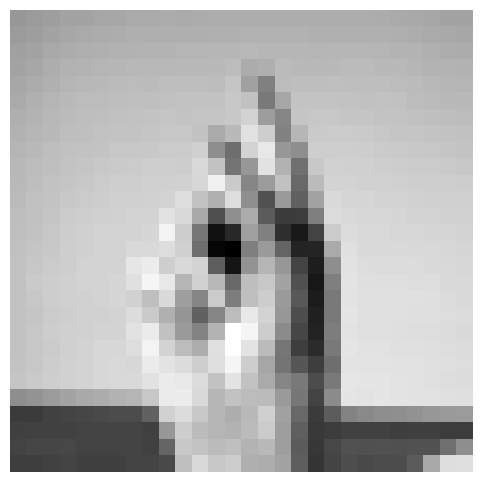

In [ ]:
#For this part we based the code from the activity 1a, and we use the rnd_index variable to store in it a random index taken from the training set.
rnd_index = np.random.randint(len(y_train))   # Select a random image for train data set

print(f'La imagen mostrada representa la letra: {alphabet[y_train[rnd_index]]}')

plot_image(x_train[rnd_index])

### **Una imagen de cada letra**

En esta celda se vuelve a leer el archivo de entrenamiento y se conserva una sola imagen por cada etiqueta, ordenadas de la primera a la última. De esta forma quedan 24 imágenes, una por cada letra disponible en el dataset. Después se define la función `plot_sample_images`, que las organiza en una cuadrícula de tres filas y las muestra con la letra correspondiente debajo de cada una. Esta vista permite comparar las señas entre sí y confirmar que las etiquetas coinciden con las imágenes.

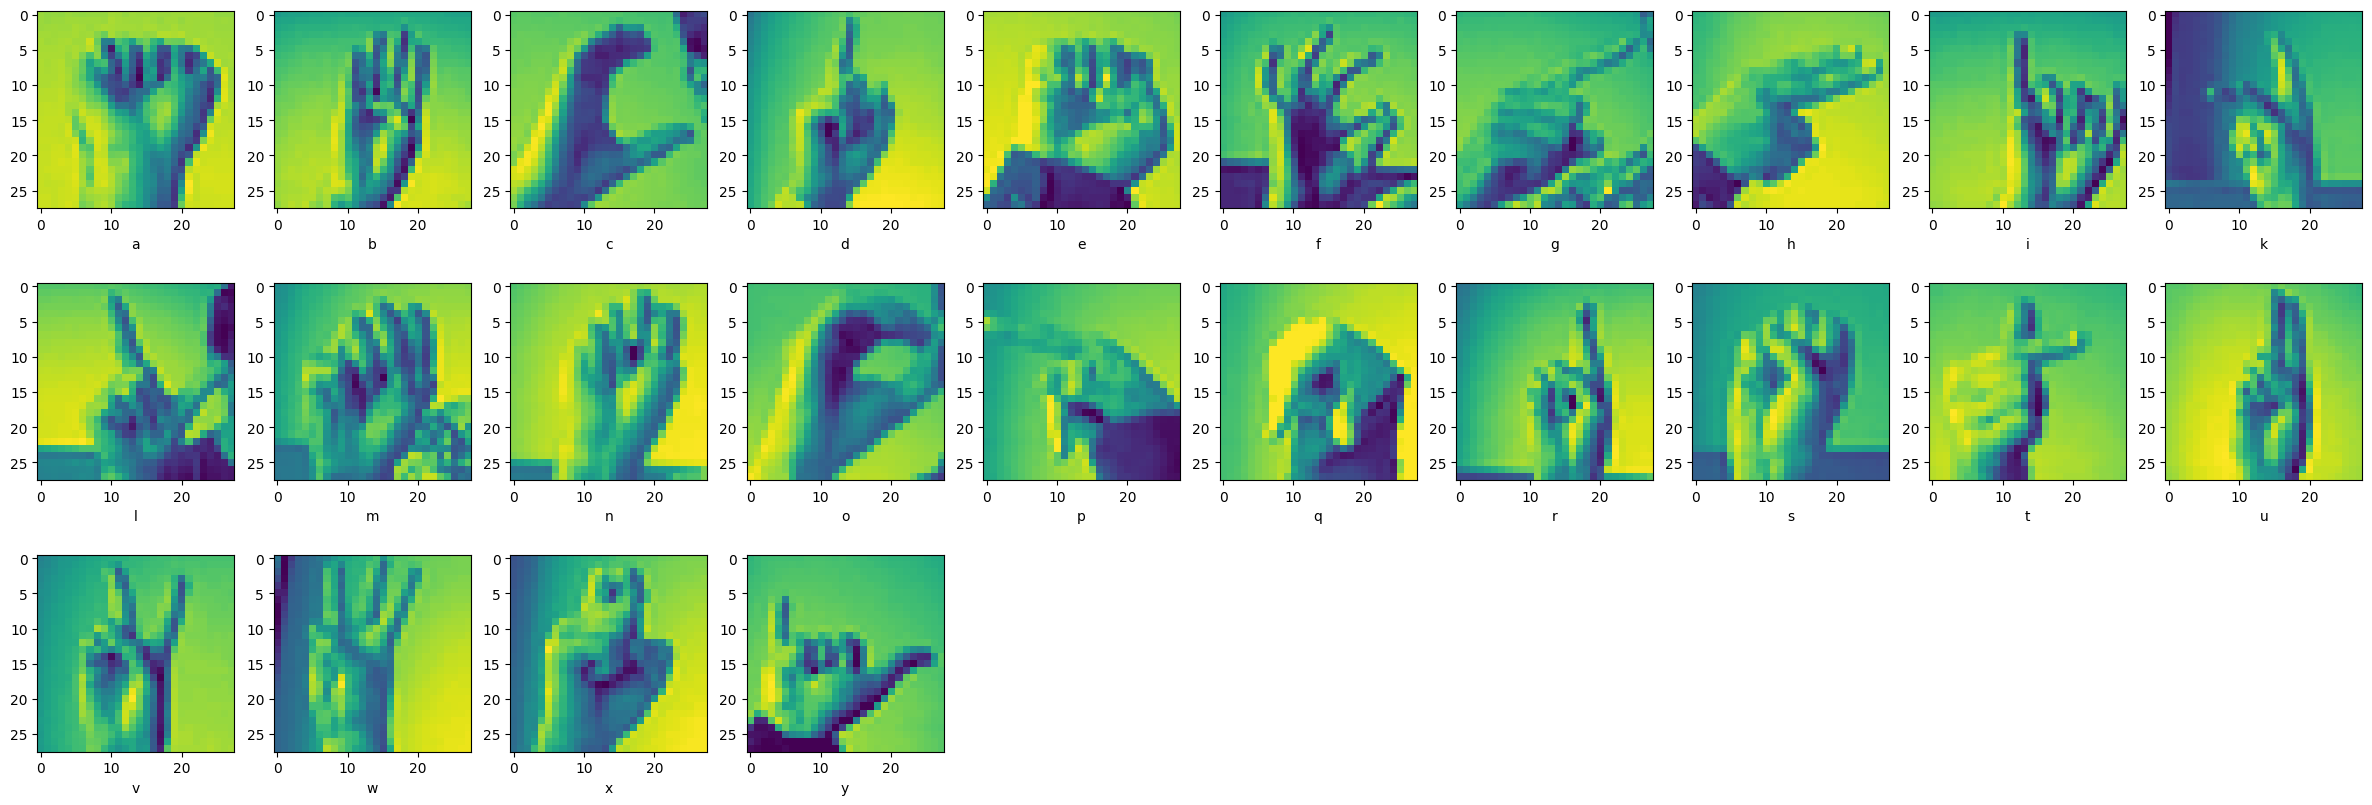

In [ ]:
#We created a variable called df_plot, to store the data from the train.csv file
df_plot = pd.read_csv(os.path.join(DATA_PATH, 'sign_mnist_train.csv'))
#Then we dropped the duplicated "labels" and sorted by label, after that we reseted the indexes, to get only the 24 images that correspond to the 24 letters in sign language.
df_plot = df_plot.drop_duplicates(subset=['label']).sort_values('label').reset_index(drop=True)
#here we dropped the column "label" to store the remaining data into the variable x_plot
x_plot = df_plot.drop(columns=['label'])

#We defined a new function to plot the unique images that represented the 24 alphabet letters.
def plot_sample_images():
    plt.figure(figsize=(30,10))

    for i in range (0,24):
        plt.subplot(3,10,i+1)
        img = x_plot.iloc[i].values.reshape(28, 28)
        value = df_plot.loc[i,'label']
        plt.imshow(img)
        plt.xlabel(alphabet[value])

plot_sample_images()

----------------------------------------------------

## **Ecuaciones de los modelos**

**Perceptrón simple**

$$z = W X + b$$

$$\hat{y} = softmax(z)$$

**Perceptrón multicapa**

$$z^1 = W^1 X + b^1$$

$$a^1 = ReLU(z^1)$$

$$z^2 = W^2 a^1 + b^2$$

$$a^2 = ReLU(z^2)$$

$$z^3 = W^3 a^2 + b^3$$

$$\hat{y} = softmax(z^3)$$

**Función de activación softmax**

$$\hat{y}_k = \frac{e^{z_k}}{\sum_j{e^{z_j}}}$$

**Función de costo**

$$\mathcal{L}(\hat{y}^{i}, y^{i}) = -\sum_k y_k^{i} \ln(\hat{y}_k^{i}) = -\ln(\hat{y}_c^{i})$$

donde $c$ es la clase correcta de la muestra $i$.

$$\mathcal{J}(w, b) = \frac{1}{num\_samples} \sum_{i=1}^{num\_samples} -\ln(\hat{y}_c^{i})$$

---------------------------------------------------------------------------

# **Funciones adicionales**

**Tamaño del mini-batch:** los valores habituales son 8, 16, 32, 128 y 512.

_________________________________________________________________________
## **Mini-batches**

Los mini-batches son subconjuntos pequeños y aleatorios del dataset que se utilizan durante el entrenamiento. Permiten cargar los datos en memoria de forma más eficiente, lo que hace posible trabajar con conjuntos de datos grandes sin agotar la memoria. En cada iteración el gradiente calculado es distinto debido a las diferencias entre mini-batches, y esa variación actúa como una forma de regularización que reduce el riesgo de que el modelo se ajuste en exceso a los datos de entrenamiento.

En lugar de usar todo el conjunto de datos a la vez, como en el descenso de gradiente por lotes, o una sola muestra, como en el descenso de gradiente estocástico, los mini-batches procesan grupos pequeños en cada paso de entrenamiento y combinan las ventajas de ambos enfoques.

El entrenamiento y la evaluación con imágenes se realizan por lotes tanto en visión computacional como en otras tareas de aprendizaje automático y aprendizaje profundo. Al procesar secciones del conjunto de datos en cada época, el entrenamiento hace un uso más eficiente de la memoria y del cómputo.

__________________________________________________________________________

### **Función para crear mini-batches**

En esta celda se define la función `create_minibatches`, que divide los datos en grupos pequeños llamados mini-batches. Primero verifica que haya el mismo número de imágenes que de etiquetas. Después, si se indica, mezcla los datos de manera aleatoria usando una lista de posiciones, de modo que cada imagen conserve su etiqueta. Por último, recorre los datos en saltos del tamaño del mini-batch y entrega cada grupo, con sus imágenes y etiquetas, uno por uno. Con esto la red puede entrenar con grupos pequeños en lugar de procesar todo el dataset de una sola vez.

In [ ]:
#Here we defined from the activite 1a, the minibatches function
def create_minibatches(mb_size, x, y, shuffle=True):
  '''
  Create mini-batches from input data.

  x muestras 784
  y muestras 1

  Args:
      mb_size (int): Size of each mini-batch.
      x (numpy.ndarray): Input data (features), where each row represents a sample.
      y (numpy.ndarray): Target data (labels), where each row corresponds to the label of the respective sample in `x`.
      shuffle (bool, optional): If True, shuffle the dataset before splitting into mini-batches. Default is True.

  Returns:
      generator: A generator yielding tuples of (mini_batch_x, mini_batch_y) for each mini-batch.
  '''

  # Ensure that the number of samples in x and y ins the same
  assert x.shape[0] == y.shape[0], 'Las dimensiones de x e y no son compatibles'

  # Total number of samples in the dataset
  total_data = x.shape[0]

  # Suffle the data if requested
  if shuffle:
    indexes = np.arange(total_data)   # Create an array of sample indices
    np.random.shuffle(indexes)        # Randomly suffle the indices
    x = x[indexes]                    # Reorder x based on the suffled indices
    y = y[indexes]                    # Reorder y based on the suffled indices

  # Create and return a generator for mini-batches
  return ((x[i:i+mb_size], y[i:i+mb_size])          # Slices for the current mini-batch
          for i in range(0, total_data, mb_size))   # Iterate in steps of mb_size

## **Clases Linear, ReLU y Sequential**

### **Clase np_tensor**

Aquí se crea la clase `np_tensor`, que funciona igual que un arreglo de NumPy pero permite guardar información adicional dentro de él. En particular, permite asignarle el atributo `.grad`, donde se almacenará el gradiente de cada valor durante el entrenamiento. Los arreglos normales de NumPy no admiten este atributo.

In [ ]:
#Also from the youtube videos and the code from activity 1a, we defined the class np_tensor, which allows us to use it as the existing np.ndarray class, but with the advantage that
#using np_tensor class we can create our own parameters for example to calculate the gradients and use ".grad" later
class np_tensor(np.ndarray): pass

--------------------------------------------------------------

## **Clase Linear**

La clase `Linear` implementa una capa totalmente conectada que calcula una transformación lineal de los datos mediante pesos y sesgos. Es equivalente a la parte lineal de un perceptrón, pero muestra paso a paso las operaciones matriciales con NumPy. Esta clase es el único componente del perceptrón simple y uno de los componentes del perceptrón multicapa.

## **Inicialización de Kaiming He**

La inicialización de He es un método para asignar los pesos iniciales de una red neuronal profunda. Se utiliza para reducir los problemas de desvanecimiento y explosión del gradiente, y está diseñada para redes con funciones de activación ReLU o con sus variantes.

Su propósito es mantener los gradientes en una escala adecuada durante la propagación, lo que permite un entrenamiento estable. Al distribuir mejor los pesos iniciales, también favorece una optimización más rápida.

El código proporcionado en clase se corrigió para esta implementación.

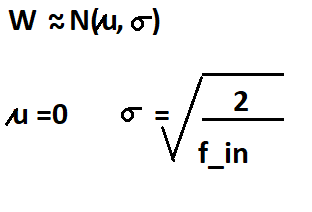

La inicialización de He se diseñó para funciones de activación ReLU. El factor raíz cuadrada de 2 entre el número de entradas mantiene la varianza de las activaciones a lo largo de las capas. En el perceptrón simple se utiliza la misma inicialización con el fin de que ambos modelos partan de condiciones equivalentes.

---

### **Clase Linear**

En esta celda se define la clase `Linear`, que representa una capa de neuronas totalmente conectada. Al crearla se indica cuántos datos recibe y cuántos genera. Sus pesos se inicializan con el método de Kaiming He, que mantiene los valores iniciales en un rango adecuado para funciones ReLU, y los sesgos comienzan en cero.

La clase tiene dos funciones principales. La función de avance multiplica los datos de entrada por los pesos y suma el sesgo para obtener la salida de la capa. La función de retroceso calcula tres gradientes: el de la entrada, que se envía a la capa anterior, el de los pesos y el del sesgo. Estos gradientes indican cuánto debe cambiar cada parámetro para reducir el error.

In [ ]:
#Here we created the class linear, using the __init__ we automatically call an instance of a class, we can
#create instances of the class with different dimensions for different layers.
class Linear():

  def __init__(self, input_size, output_size):
    '''
    Initialize parameters using Kaiming He initialization.

    Args:
        input_size (int): Number of input features (size of the input vector).
        output_size (int): Number of output features (size of the output vector).
    '''

    # Kaiming He initialization for weights
    self.W = (np.random.randn(output_size, input_size) * np.sqrt(2/input_size)).view(np_tensor)

    # Bias initialization (Usuarlly zeros)
    self.b = (np.zeros((output_size, 1))).view(np_tensor)

#For the forward function we will use __call__ method, which allows the object to behave like a function, enabling integration
#and automatically passes from the first layer to the next one
  def __call__(self, X):
    '''
    Forward pass for the linear layer.

    Args:
        X (np.ndarray): Input data of shap (batch_size, input_size).

    Returns:
        np.ndarray: Output of the linear transformation, shape (batch_size, output_size).
    '''
    Z = self.W @ X + self.b
    return Z

#We defined a function for the backpropagation method, here we need X which is our input, and Z which is our output, and we want to start getting
#our gradients.
  def backward(self, X, Z):
    '''
    Backward passs for the linear layer.
    Computes gradients with respect to the input, weights, and bias

    Args:
        X (np.ndarray): Input data of shape (batch_size, input_size).
        Z (np.ndarray): Output of the layer from the forward pass.
    '''

    # Gradient of the input (propagated backward)
    X.grad = self.W.T @ Z.grad

    # Gradient of the weights
    self.W.grad = Z.grad @ X.T

    # Gradient of the bias (sum over batch axis)
    self.b.grad = np.sum(Z.grad, axis=1, keepdims=True)

--------------------------------------------------------------------------

## **Clase ReLU**

La función ReLU es una función de activación sencilla que reduce el costo computacional, disminuye el riesgo de desvanecimiento del gradiente y permite un aprendizaje más rápido. Convierte en cero los valores negativos y conserva los positivos, con lo que introduce la no linealidad necesaria para que la red aprenda patrones complejos y realice tareas de clasificación.

Las redes neuronales requieren funciones no lineales para aprender representaciones complejas, ya que una sucesión de capas únicamente lineales equivale a una sola transformación lineal.

La función ReLU se define como:

    ReLU(Z) = max(0, Z)

----------------------------------------------------------------------

### **Clase ReLU**

En esta celda se define la función de activación ReLU, que se coloca después de cada capa lineal para que la red pueda aprender relaciones complejas. En el avance, la función conserva los valores positivos y convierte los negativos en cero. En el retroceso, el gradiente se copia de la salida a la entrada y se pone en cero en las posiciones donde el valor era negativo o cero, ya que en esos casos la neurona estaba inactiva y no aportó al resultado.

In [ ]:
#Here we define the Rectified Linear Unit Class to ensure non-linearity in our model
class ReLU():

  #We defined a forward function, using the method of __call__ to automatically run the forward pass, and we need the parameters self, and Z which is our output.
  def __call__(self, Z):
    '''
    Forward pass of the ReLU activation function.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.

    Returns:
        np.ndarray: Output tensor after applying the ReLU activation function.
    '''

    return np.maximum(0, Z)

  #Our backward function, works exactly the same,  to get the gradients of the loss function with respect to Z.
  def backward(self, Z, A):
    '''
    Backward pass of the ReLU activation function.

    Compute the gradient of the loss with respect to the input Z,
    based on the gradient of the output A.

    Args:
        Z (np.ndarray): Input tensor, typically the output of a linear layer.
        A (np.ndarray): Output tensor after applying the ReLU activation function.
    '''

    # Copy the gradient from A (output) to Z (input)
    Z.grad = A.grad.copy()

    # Set gradients to 0 where Z <= 0 (ReLU is inactive for negative inputs)
    Z.grad[Z <= 0] = 0

--------------------------------------------------------------------------

## **Clase Sequential**

La clase `Sequential` integra las capas lineales y las funciones de activación en orden secuencial. Permite realizar el avance, el retroceso, la actualización de parámetros y la predicción de la red. Se utiliza tanto para el perceptrón simple, que tiene una sola capa, como para el perceptrón multicapa.

--------------------------------------------------------------------------

### **Clase Sequential_layers**

Esta clase une todas las capas en una sola red. Recibe una lista con las capas lineales y las activaciones, en el orden en que deben ejecutarse. Tiene cuatro funciones:

- **Avance:** pasa los datos por cada capa en orden y guarda la salida de cada una en un diccionario, para usarla después en el cálculo de gradientes. Entrega los puntajes finales de cada clase.
- **Retroceso:** recorre las capas en orden inverso, de la última a la primera, y calcula los gradientes de cada una con las salidas guardadas.
- **Actualización:** ajusta los pesos y sesgos de cada capa lineal restándoles su gradiente multiplicado por la tasa de aprendizaje. Las capas ReLU se omiten porque no tienen parámetros.
- **Predicción:** obtiene los puntajes de la red y elige la clase con el puntaje más alto para cada imagen.

In [ ]:
#Here the sequential_layers class, is created to run the data through the Linear class and the ReLU class:
class Sequential_layers():

  #We create the __init__ to automatically initialize the sequence.
  def __init__(self, layers):
    '''
    Initialize the sequential model.

    Args:
        layers (list): List of layers to be stacked in the sequential model.
    '''

    # Store the layers
    self.layers = layers

    # Placeholder for input data (stores the initial layer)
    self.x = None

    # Directionary to store intermediate outputs for each layer
    self.outputs = {}

#The _call__ function works as the forward method for the layers
  def __call__(self, X):
    '''
    Perform the forward pass through all layers.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: The final output of the network (scores for classification).
    '''

    # Store the initial input
    self.x = X

    # Save the input as the output of "layer 0"
    self.outputs['l0'] = self.x

    # Iterate through all layers and perform forward propagation
    for i, layer in enumerate(self.layers, 1):
      self.x = layer(self.x)    # Pass the output of the previous layer to the next

      self.outputs['l' + str(i)] = self.x   # Store the output for this layer

    return self.x   # Retun the final output

#The backward function helps us to calculate the gradients.
  def backward(self):
    '''
    Perform the backward pass through all layers (in reverse order).

    Uses the stored outputs to calculate gradients for each layer.
    '''

    # Iterate over layers in reverse order
    for i in reversed(range(len(self.layers))):

      # Compute gradients for each layer based on the outputs of the current and next layer
      self.layers[i].backward(self.outputs['l' + str(i)], self.outputs['l' + str(i + 1)])

#Finally the update function we created, will take the result from the backward function and update the values for w and b, based on the learning rate.
  def update(self, learning_rate=1e-3):
    '''
    Update the parameters of all layers using gradient descent.

    Args:
        learning_rate (float, optional): Learning rate for gradient descent. Default is 1e-3.
    '''

    # Iterate through all layers and update their parameters
    for layer in self.layers:

      # Skip activation layers (ReLU does not have parameters to update)
      if isinstance(layer, ReLU): continue

      # Update weights and biases using gradients descent
      layer.W = layer.W - learning_rate * layer.W.grad
      layer.b = layer.b - learning_rate * layer.b.grad

#Here we define the predict function, to make the predictions using the trained model
  def predict(self, X):
    '''
    Make predictions using the trained model.

    Args:
        X (np.ndarray): Input data of shape (input_size, batch_size).

    Returns:
        np.ndarray: Predicted scores for each class.
    '''

    return np.argmax(self.__call__(X), axis=0)


--------------------------------------------------------------------------

## **Función de costo**

La función de costo mide el error de un modelo durante el entrenamiento. Su propósito es indicar qué tan lejos están las predicciones de los valores reales. Mientras mayor es el valor de la función de costo, mayor es el error del modelo. El entrenamiento consiste en minimizar esta función mediante el ajuste de los pesos de la red, de modo que las predicciones se acerquen a los valores reales. La función de costo guía al algoritmo de entrenamiento en el ajuste de los pesos a lo largo de las iteraciones.

------------------------------------------------------------------------

### **Función de costo**

En esta celda se define la función `softmaxXEntropy`, que mide qué tan equivocadas están las predicciones de la red. Primero convierte los puntajes de cada clase en probabilidades mediante la función softmax, de modo que sumen uno para cada imagen. Después toma la probabilidad asignada a la clase correcta y calcula el costo como el promedio de su logaritmo negativo en el mini-batch. Un costo alto indica que la red asignó poca probabilidad a la letra correcta. Por último, calcula el gradiente restando uno a la probabilidad de la clase correcta, que es el punto de partida del retroceso.

In [ ]:
#We define here the function softmaxXEntropy which will get the scores, and calculate the probabilities
def softmaxXEntropy(x, y):
  '''
  Compute the softmax cross-entropy loss and its gradient.

  Args:
      x (np.ndarray): Scores (logits) from the model of shape
      y (np.ndarray): True class labels of shape

  Returns:
      preds (np.ndarray): Predicted class probabilities.
      cost (float): The average softmax cross-entropy loss across the batch.
  '''

  # Number of samples in the batch
  batch_size = x.shape[1]

  # Compute the softmax probabilities
  exp_scores = np.exp(x - x.max(axis=0, keepdims=True))   # Se resta el máximo de cada columna para evitar desbordamiento (no cambia el resultado)
  probs = exp_scores / exp_scores.sum(axis=0)  # Normalize to get probabilities
  preds = probs.copy()                          # Save predictions for output

  # Compute the cross/entropy loss
  y_hat = probs[y.squeeze(), np.arange(batch_size)]   # Select the probabilities corresponding to the true classes
  cost = np.sum(-np.log(np.clip(y_hat, 1e-12, None))) / batch_size   # clip evita log(0)          # Average loss over the batch

  # Compute the gradient
  probs[y.squeeze(), np.arange(batch_size)] -= 1       # gradient dl/dx (Subtract 1 from the correct classes)
  x.grad = probs.copy()

  return preds, cost

## **Ciclo de entrenamiento**

### Función de entrenamiento

En esta celda se define la función `train`, que entrena la red durante el número de épocas indicado. Una época es una pasada completa por todo el conjunto de entrenamiento. En cada época los datos se dividen en mini-batches y, para cada uno, se realizan cuatro pasos. Primero se obtienen los puntajes de la red con el avance. Después se calcula el costo y su gradiente. Luego se calculan los gradientes de cada capa con el retroceso. Finalmente se actualizan los pesos y sesgos según la tasa de aprendizaje. Al terminar cada época se imprime el número de época, el costo promedio de los mini-batches y la exactitud sobre el conjunto de validación.

La función recibe como parámetro el modelo que se entrena, por lo que sirve tanto para el perceptrón simple como para el perceptrón multicapa. Además devuelve un historial con el costo y la exactitud de cada época, que se utiliza más adelante para graficar la comparación entre los modelos.

In [ ]:
def train(model, epochs, mb_size=128, learning_rate=1e-3, nombre='Modelo'):
  '''
  Entrena el modelo con descenso de gradiente por mini-batches.

  Args:
      model (Sequential_layers): red neuronal que se entrena.
      epochs (int): número de épocas.
      mb_size (int, optional): tamaño de cada mini-batch.
      learning_rate (float, optional): tasa de aprendizaje para actualizar los parámetros.
      nombre (str, optional): etiqueta para identificar el modelo en la impresión.

  Returns:
      dict: historial con el costo promedio y la exactitud de validación de cada época.
  '''
  historial = {'costo': [], 'acc_val': []}

  for epoch in range(epochs):
    costos = []

    # Recorre los mini-batches
    for i, (x, y) in enumerate(create_minibatches(mb_size, x_train, y_train)):

      # Avance: calcula los puntajes
      scores = model(x.T.view(np_tensor))   # Se transpone x para que sea compatible

      # Calcula el costo y su gradiente
      _, cost = softmaxXEntropy(scores, y)
      costos.append(cost)

      # Retroceso: calcula los gradientes
      model.backward()

      # Actualiza los parámetros del modelo
      model.update(learning_rate)

    historial['costo'].append(np.mean(costos))
    historial['acc_val'].append(accuracy(x_val, y_val, mb_size, model))
    print(f'{nombre} | Época: {epoch}, costo promedio: {historial["costo"][-1]:.5f}, accuracy val: {historial["acc_val"][-1]:.4f}')

  return historial

### Función de exactitud

Esta celda define la función `accuracy`, que calcula el porcentaje de imágenes que la red clasifica correctamente. Recibe como parámetro el modelo que se evalúa. Recorre los datos por mini-batches, obtiene los puntajes de la red y elige la clase con el puntaje más alto para cada imagen. Después compara esa clase con la etiqueta real y cuenta los aciertos. Al final divide el total de aciertos entre el total de imágenes evaluadas. Se usa tanto durante el entrenamiento, con los datos de validación, como al final, con los datos de prueba.

In [ ]:
def accuracy(x, y, mb_size, model):
  '''
  Calcula la exactitud del modelo sobre un conjunto de datos.

  Args:
      x (np.ndarray): imágenes de entrada.
      y (np.ndarray): etiquetas reales.
      mb_size (int): tamaño de los mini-batches para la evaluación.
      model (Sequential_layers): modelo que se evalúa.

  Returns:
      float: exactitud del modelo, aciertos entre total de muestras.
  '''
  correct_predictions = 0
  total_samples = 0

  # Recorre los mini-batches
  for xb, yb in create_minibatches(mb_size, x, y):

    # Avance: puntajes de cada clase
    preds = model(xb.T.view(np_tensor))

    # Compara las clases predichas con las etiquetas reales
    correct_predictions += np.sum(np.argmax(preds, axis=0) == yb.squeeze())

    # Número de muestras del mini-batch actual
    total_samples += preds.shape[1]

  return correct_predictions / total_samples

## **Creación y entrenamiento de los modelos**

# **Justificación de la arquitectura**

Se entrenan dos modelos con los mismos datos, la misma función de costo, la misma inicialización y los mismos hiperparámetros. De esta manera, la diferencia entre sus resultados se atribuye a la arquitectura.

## Capa de entrada
- Las imágenes miden 28 por 28 pixeles, por lo que la capa de entrada recibe **784 valores**, uno por cada pixel normalizado.

## Capa de salida
- La salida tiene **24 neuronas**, una por cada letra del dataset. Las letras J y Z se excluyen porque su representación requiere movimiento y el dataset contiene imágenes fijas. La salida pasa por la función softmax para obtener una probabilidad por clase.

## Perceptrón simple
- Consta de una sola capa lineal de 784 entradas a 24 salidas, sin capas ocultas ni activaciones intermedias, y tiene 18,840 parámetros. Cada clase recibe un puntaje que es una combinación lineal de los pixeles, por lo que el modelo separa las clases únicamente mediante fronteras lineales.
- El perceptrón original utiliza una función escalón y una regla de actualización propia. En este notebook se emplea la salida softmax con la función de costo de entropía cruzada, lo que permite entrenarlo con el mismo procedimiento de descenso de gradiente que el perceptrón multicapa.

## Perceptrón multicapa
- **Capas ocultas:** dos capas lineales de 256 y 128 neuronas. El número de neuronas disminuye de una capa a la siguiente hasta llegar a las 24 clases, y el modelo completo tiene 236,952 parámetros.
- **Activación ReLU:** se aplica después de cada capa oculta. Introduce no linealidad, lo que permite representar relaciones que una combinación lineal no puede capturar. Su gradiente vale 0 o 1, lo que reduce el riesgo de desvanecimiento del gradiente, y su cálculo es más sencillo que el de las funciones sigmoide o tangente hiperbólica.
- **Inicialización de He:** el factor raíz cuadrada de 2 entre el número de entradas mantiene la escala de las activaciones al usar ReLU.

## Hiperparámetros
- **Épocas:** ambos modelos se entrenan durante 30 épocas, cantidad con la que la exactitud de validación del perceptrón multicapa ya se encuentra estabilizada.
- **Mini-batch y tasa de aprendizaje:** se utilizan mini-batches de 128 imágenes y una tasa de aprendizaje de 0.004 en los dos modelos.

### **Creación de los modelos**

Aquí se definen las dos arquitecturas y sus hiperparámetros. En el perceptrón multicapa, la primera capa recibe las 784 características de cada imagen y genera 256 salidas. La segunda capa recibe esas 256 salidas y genera 128, y la capa de salida genera 24 valores, uno por cada letra. Después de cada una de las dos primeras capas se aplica la función ReLU. El perceptrón simple conecta directamente las 784 características con las 24 salidas mediante una sola capa lineal, que se define en la sección siguiente. Ambos modelos se entrenan con mini-batches de 128 imágenes, una tasa de aprendizaje de 0.004 y 30 épocas.

In [ ]:
mb_size = 128
learning_rate = 4e-3
epochs = 30

# Perceptrón multicapa
np.random.seed(42)
model = Sequential_layers([Linear(784, 256), #primera capa lineal (recibe 784 datos de entrada, genera 256 salidas)
                           ReLU(),           #activacion de la primera capa
                           Linear(256, 128), #segunda capa lineal (recibe 256 datos de entrada, genera 128 salidas)
                           ReLU(),           #activacion de la segunda capa
                           Linear(128, 24)]) #capa de salida (genera 24 salidas, una por clase)

In [ ]:
hist_mlp = train(model, epochs, mb_size, learning_rate, nombre='Multicapa')

Multicapa | Época: 0, costo promedio: 0.72624, accuracy val: 0.7906
Multicapa | Época: 1, costo promedio: 0.00493, accuracy val: 0.7989
Multicapa | Época: 2, costo promedio: 0.00206, accuracy val: 0.7956
Multicapa | Época: 3, costo promedio: 0.00130, accuracy val: 0.8001
Multicapa | Época: 4, costo promedio: 0.00095, accuracy val: 0.8012
Multicapa | Época: 5, costo promedio: 0.00074, accuracy val: 0.8034
Multicapa | Época: 6, costo promedio: 0.00061, accuracy val: 0.8026
Multicapa | Época: 7, costo promedio: 0.00051, accuracy val: 0.8054
Multicapa | Época: 8, costo promedio: 0.00044, accuracy val: 0.8048
Multicapa | Época: 9, costo promedio: 0.00039, accuracy val: 0.8073
Multicapa | Época: 10, costo promedio: 0.00034, accuracy val: 0.8056
Multicapa | Época: 11, costo promedio: 0.00031, accuracy val: 0.8081
Multicapa | Época: 12, costo promedio: 0.00028, accuracy val: 0.8076
Multicapa | Época: 13, costo promedio: 0.00026, accuracy val: 0.8076
Multicapa | Época: 14, costo promedio: 0.000

In [ ]:
acc_test_mlp = accuracy(x_test, y_test, mb_size, model)
print(f'Accuracy en prueba del perceptrón multicapa: {acc_test_mlp:.4f}')

Accuracy en prueba del perceptrón multicapa: 0.8009


### **Perceptrón simple**

En esta sección se entrena un perceptrón simple con los mismos datos, la misma función de costo y los mismos hiperparámetros que el perceptrón multicapa. El modelo consta de una sola capa lineal que conecta los 784 pixeles de entrada con las 24 clases de salida, sin capas ocultas ni activaciones intermedias. Cada clase recibe un puntaje que resulta de una combinación lineal de los pixeles, y la función softmax convierte esos puntajes en probabilidades. Con esta estructura el modelo solo puede separar las clases mediante fronteras lineales.

In [ ]:
# Perceptrón simple: una sola capa lineal de 784 entradas a 24 salidas
np.random.seed(42)
perceptron = Sequential_layers([Linear(784, 24)])

hist_per = train(perceptron, epochs, mb_size, learning_rate, nombre='Simple')

Simple | Época: 0, costo promedio: 1.34425, accuracy val: 0.6598
Simple | Época: 1, costo promedio: 0.07888, accuracy val: 0.6838
Simple | Época: 2, costo promedio: 0.03944, accuracy val: 0.6863
Simple | Época: 3, costo promedio: 0.02901, accuracy val: 0.6871
Simple | Época: 4, costo promedio: 0.02359, accuracy val: 0.6919
Simple | Época: 5, costo promedio: 0.01996, accuracy val: 0.6949
Simple | Época: 6, costo promedio: 0.01738, accuracy val: 0.6880
Simple | Época: 7, costo promedio: 0.01541, accuracy val: 0.6871
Simple | Época: 8, costo promedio: 0.01390, accuracy val: 0.6902
Simple | Época: 9, costo promedio: 0.01269, accuracy val: 0.6835
Simple | Época: 10, costo promedio: 0.01167, accuracy val: 0.6919
Simple | Época: 11, costo promedio: 0.01076, accuracy val: 0.6857
Simple | Época: 12, costo promedio: 0.01001, accuracy val: 0.6891
Simple | Época: 13, costo promedio: 0.00938, accuracy val: 0.6907
Simple | Época: 14, costo promedio: 0.00882, accuracy val: 0.6868
Simple | Época: 15, 

In [ ]:
acc_test_per = accuracy(x_test, y_test, mb_size, perceptron)
print(f'Accuracy en prueba del perceptrón simple: {acc_test_per:.4f}')

Accuracy en prueba del perceptrón simple: 0.6656


## **Prueba de los modelos con datos aleatorios del conjunto de prueba**

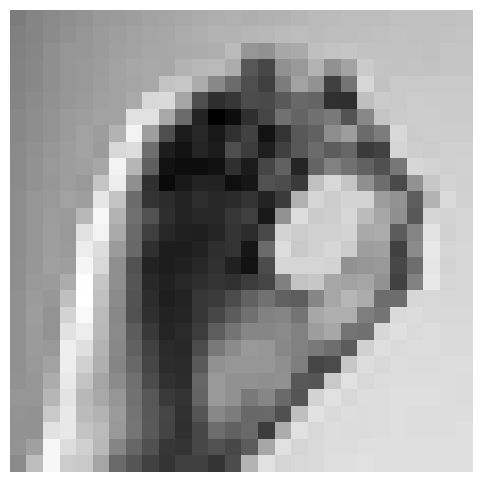

La letra real es: o
Predicción del perceptrón multicapa: o
Predicción del perceptrón simple: o


In [ ]:
idx = np.random.randint(len(y_test))
plot_image(x_test[idx].reshape(28,28))

x_uno = x_test[idx].reshape(-1, 1)
pred_mlp = model.predict(x_uno)
pred_per = perceptron.predict(x_uno)

print(f'La letra real es: {alphabet[y_test[idx]]}')
print(f'Predicción del perceptrón multicapa: {alphabet[pred_mlp[0]]}')
print(f'Predicción del perceptrón simple: {alphabet[pred_per[0]]}')

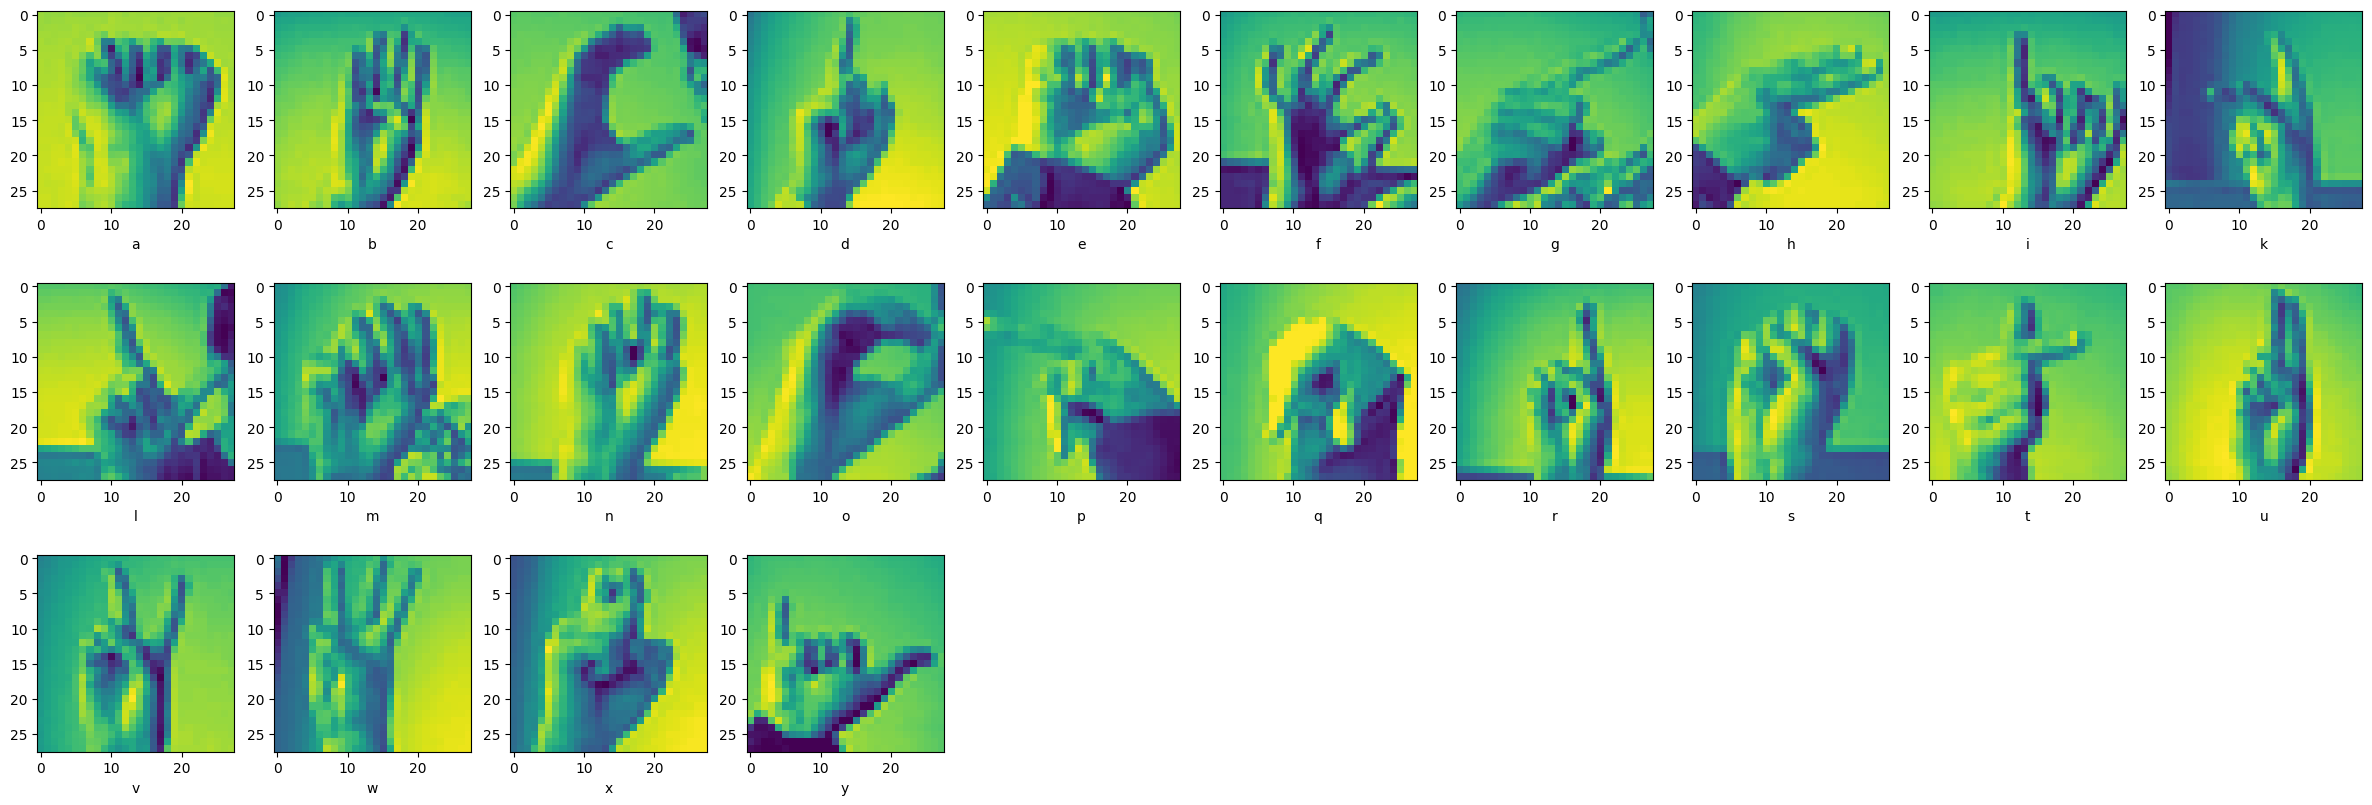

In [ ]:
plot_sample_images()

## **Comparación entre el perceptrón simple y el perceptrón multicapa**

Las siguientes celdas reúnen las métricas de ambos modelos en una tabla y en una figura. La figura contiene tres paneles. El primero muestra la evolución del costo de entrenamiento por época en escala logarítmica. El segundo muestra la exactitud de validación por época e indica la época con el valor más alto de cada modelo, y el área sombreada entre las curvas representa la diferencia entre ambos. El tercero muestra la exactitud de cada modelo en el conjunto de prueba, que no se utilizó durante el ajuste, junto con el número de parámetros de cada arquitectura.

In [ ]:
def contar_parametros(modelo):
  '''Cuenta los pesos y sesgos de las capas lineales de un modelo.'''
  return sum(capa.W.size + capa.b.size for capa in modelo.layers if isinstance(capa, Linear))

resultados = pd.DataFrame({
    'Modelo': ['Perceptrón simple', 'Perceptrón multicapa'],
    'Capas ocultas': [0, 2],
    'Parámetros': [contar_parametros(perceptron), contar_parametros(model)],
    'Costo final': [hist_per['costo'][-1], hist_mlp['costo'][-1]],
    'Accuracy validación final': [hist_per['acc_val'][-1], hist_mlp['acc_val'][-1]],
    'Accuracy validación máxima': [max(hist_per['acc_val']), max(hist_mlp['acc_val'])],
    'Accuracy prueba': [acc_test_per, acc_test_mlp]
})

resultados.round(4)

,Modelo,Capas ocultas,Parámetros,Costo final,Accuracy validación final,Accuracy validación máxima,Accuracy prueba
0,Perceptrón simple,0,18840,0.0047,0.6848856664807585,0.6949247071946458,0.6656441717791411
1,Perceptrón multicapa,2,236952,0.0001,0.8098159509202454,0.8109313998884551,0.8008923591745678


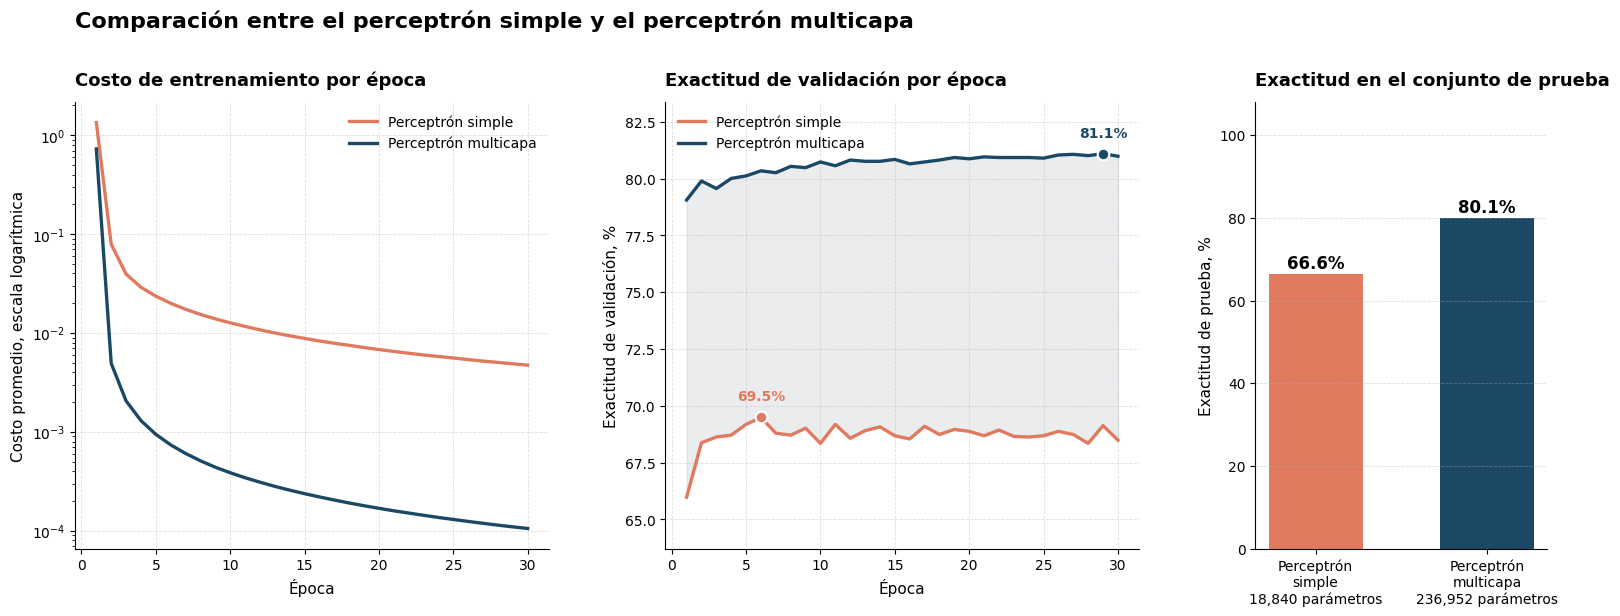

In [ ]:
import matplotlib.gridspec as gridspec

color_per = '#E07A5F'
color_mlp = '#1B4965'
epocas = np.arange(1, epochs + 1)

def estilo_ejes(ax, titulo, xlabel, ylabel):
  ax.set_title(titulo, fontsize=13, fontweight='bold', loc='left', pad=12)
  ax.set_xlabel(xlabel, fontsize=11)
  ax.set_ylabel(ylabel, fontsize=11)
  ax.grid(True, linestyle='--', linewidth=0.6, alpha=0.4)
  for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
  ax.tick_params(labelsize=10)

acc_per = np.array(hist_per['acc_val']) * 100
acc_mlp = np.array(hist_mlp['acc_val']) * 100

fig = plt.figure(figsize=(19, 5.8))
gs = gridspec.GridSpec(1, 3, width_ratios=[1.3, 1.3, 0.8], wspace=0.28)

# Panel 1: costo de entrenamiento por época
ax1 = fig.add_subplot(gs[0])
ax1.plot(epocas, hist_per['costo'], color=color_per, linewidth=2.4, label='Perceptrón simple')
ax1.plot(epocas, hist_mlp['costo'], color=color_mlp, linewidth=2.4, label='Perceptrón multicapa')
ax1.set_yscale('log')
estilo_ejes(ax1, 'Costo de entrenamiento por época', 'Época', 'Costo promedio, escala logarítmica')
ax1.legend(frameon=False, fontsize=10)

# Panel 2: exactitud de validación por época
ax2 = fig.add_subplot(gs[1])
ax2.plot(epocas, acc_per, color=color_per, linewidth=2.4, label='Perceptrón simple')
ax2.plot(epocas, acc_mlp, color=color_mlp, linewidth=2.4, label='Perceptrón multicapa')
ax2.fill_between(epocas, acc_per, acc_mlp, color='#adb5bd', alpha=0.25)
for acc, color in [(acc_per, color_per), (acc_mlp, color_mlp)]:
  mejor = int(np.argmax(acc))
  ax2.scatter(epocas[mejor], acc[mejor], s=70, color=color, zorder=5, edgecolor='white', linewidth=1.5)
  ax2.annotate(f'{acc[mejor]:.1f}%', (epocas[mejor], acc[mejor]), textcoords='offset points',
               xytext=(0, 12), ha='center', fontsize=10, fontweight='bold', color=color)
ax2.margins(y=0.15)
estilo_ejes(ax2, 'Exactitud de validación por época', 'Época', 'Exactitud de validación, %')
ax2.legend(frameon=False, fontsize=10, loc='best')

# Panel 3: exactitud en el conjunto de prueba
ax3 = fig.add_subplot(gs[2])
nombres = [f'Perceptrón\nsimple\n{contar_parametros(perceptron):,} parámetros',
           f'Perceptrón\nmulticapa\n{contar_parametros(model):,} parámetros']
valores = [acc_test_per * 100, acc_test_mlp * 100]
barras = ax3.bar(nombres, valores, color=[color_per, color_mlp], width=0.55)
for barra, valor in zip(barras, valores):
  ax3.text(barra.get_x() + barra.get_width() / 2, valor + 1.2, f'{valor:.1f}%',
           ha='center', fontsize=12, fontweight='bold')
ax3.set_ylim(0, 108)
estilo_ejes(ax3, 'Exactitud en el conjunto de prueba', '', 'Exactitud de prueba, %')
ax3.grid(axis='x', visible=False)

fig.suptitle('Comparación entre el perceptrón simple y el perceptrón multicapa',
             fontsize=16, fontweight='bold', x=0.125, ha='left', y=1.04)

plt.savefig('comparacion_perceptrones.png', dpi=200, bbox_inches='tight')
plt.show()

# **Interpretación de resultados**

In [ ]:
from IPython.display import Markdown, display

def describir_entrenamiento(nombre, hist, acc_test):
  # Genera el texto de interpretación de un modelo a partir de su historial
  acc = np.array(hist['acc_val']) * 100
  costo = np.array(hist['costo'])
  mejor = int(np.argmax(acc))
  dif_max_final = acc.max() - acc[-1]
  dif_val_test = acc[-1] - acc_test * 100
  return f"""
### {nombre}

- **Aprendizaje inicial:** en la época 0 el modelo alcanzó una exactitud de validación de {acc[0]:.1f}% y en la época {len(acc) - 1} alcanzó {acc[-1]:.1f}%. El costo promedio pasó de {costo[0]:.4f} a {costo[-1]:.5f} en el mismo intervalo.

- **Punto más alto de la exactitud:** el valor máximo de la exactitud de validación fue {acc.max():.1f}% en la época {mejor}. La diferencia entre ese máximo y el valor de la última época fue de {dif_max_final:.1f} puntos porcentuales.

- **Resultado en el conjunto de prueba:** la exactitud fue de {acc_test * 100:.1f}%, frente a {acc[-1]:.1f}% en validación al terminar el entrenamiento, lo que representa una diferencia de {abs(dif_val_test):.1f} puntos porcentuales. Como la validación se usó para observar el entrenamiento y la prueba no, la cifra de prueba es la que representa el desempeño esperado con imágenes nuevas. Aproximadamente {100 - acc_test * 100:.1f}% de las imágenes de prueba se clasificó de forma incorrecta.
"""

display(Markdown(describir_entrenamiento('Perceptrón simple', hist_per, acc_test_per)
                 + describir_entrenamiento('Perceptrón multicapa', hist_mlp, acc_test_mlp)))


### Perceptrón simple

- **Aprendizaje inicial:** en la época 0 el modelo alcanzó una exactitud de validación de 66.0% y en la época 29 alcanzó 68.5%. El costo promedio pasó de 1.3442 a 0.00473 en el mismo intervalo.

- **Punto más alto de la exactitud:** el valor máximo de la exactitud de validación fue 69.5% en la época 5. La diferencia entre ese máximo y el valor de la última época fue de 1.0 puntos porcentuales.

- **Resultado en el conjunto de prueba:** la exactitud fue de 66.6%, frente a 68.5% en validación al terminar el entrenamiento, lo que representa una diferencia de 1.9 puntos porcentuales. Como la validación se usó para observar el entrenamiento y la prueba no, la cifra de prueba es la que representa el desempeño esperado con imágenes nuevas. Aproximadamente 33.4% de las imágenes de prueba se clasificó de forma incorrecta.

### Perceptrón multicapa

- **Aprendizaje inicial:** en la época 0 el modelo alcanzó una exactitud de validación de 79.1% y en la época 29 alcanzó 81.0%. El costo promedio pasó de 0.7262 a 0.00011 en el mismo intervalo.

- **Punto más alto de la exactitud:** el valor máximo de la exactitud de validación fue 81.1% en la época 28. La diferencia entre ese máximo y el valor de la última época fue de 0.1 puntos porcentuales.

- **Resultado en el conjunto de prueba:** la exactitud fue de 80.1%, frente a 81.0% en validación al terminar el entrenamiento, lo que representa una diferencia de 0.9 puntos porcentuales. Como la validación se usó para observar el entrenamiento y la prueba no, la cifra de prueba es la que representa el desempeño esperado con imágenes nuevas. Aproximadamente 19.9% de las imágenes de prueba se clasificó de forma incorrecta.


### Factores que influyen en los errores

- **Resolución de las imágenes:** las imágenes tienen un tamaño de 28 por 28 pixeles. En la muestra de las 24 letras se aprecia que a esta resolución los dedos y los contornos de la mano ocupan pocos pixeles, lo que reduce los detalles que diferencian a señas similares.

- **Variación entre imágenes:** la muestra también presenta diferencias en la posición de la mano, el tamaño con que aparece, el fondo y la iluminación. Estas variaciones hacen que una misma letra pueda verse distinta entre imágenes, y en las pruebas con imágenes aleatorias pueden observarse confusiones entre letras de forma parecida.

- **Tipo de red:** una red completamente conectada recibe cada pixel como una entrada independiente y no aprovecha de forma directa la relación entre pixeles vecinos, que define los bordes y las formas. Esta característica es común al perceptrón simple y al perceptrón multicapa.

## **Análisis de errores del perceptrón multicapa**

La exactitud total no dice **cuáles** letras se confunden. Aquí se calcula la matriz de confusión del perceptrón multicapa sobre el conjunto de prueba, la exactitud por letra y las parejas de letras que más se confunden. Con esto se respaldan con datos los factores de error que se describieron arriba.

In [ ]:
n_clases = len(alphabet)   # 24 letras

def predecir_en_lotes(modelo, x, tam=512):
  '''Devuelve la clase predicha para cada imagen de x, procesando por lotes.'''
  preds = []
  for i in range(0, len(x), tam):
    puntajes = modelo(x[i:i+tam].T.view(np_tensor))
    preds.append(np.argmax(puntajes, axis=0))
  return np.concatenate(preds)

pred_test_mlp = predecir_en_lotes(model, x_test)
pred_test_per = predecir_en_lotes(perceptron, x_test)

# Matriz de confusión: renglones = letra real, columnas = letra predicha
matriz = np.zeros((n_clases, n_clases), dtype=int)
for real, pred in zip(y_test, pred_test_mlp):
  matriz[real, pred] += 1

print('Exactitud recalculada (multicapa):', round(np.mean(pred_test_mlp == y_test), 4))
print('Exactitud recalculada (simple):   ', round(np.mean(pred_test_per == y_test), 4))

Exactitud recalculada (multicapa): 0.8009
Exactitud recalculada (simple):    0.6656


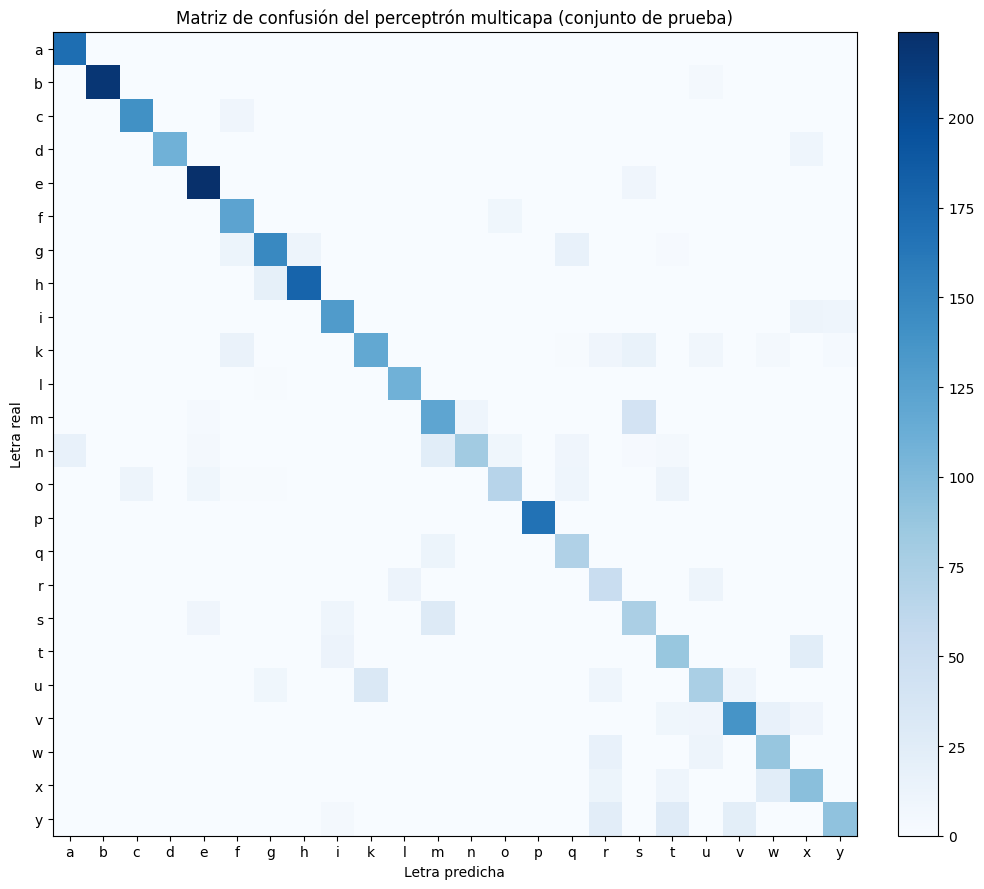

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(matriz, cmap='Blues')
ax.set_xticks(range(n_clases)); ax.set_xticklabels(alphabet)
ax.set_yticks(range(n_clases)); ax.set_yticklabels(alphabet)
ax.set_xlabel('Letra predicha')
ax.set_ylabel('Letra real')
ax.set_title('Matriz de confusión del perceptrón multicapa (conjunto de prueba)')
plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### **Exactitud por letra**

Se compara la exactitud de cada letra entre el perceptrón simple y el multicapa. Las letras con barras más bajas son las más difíciles de reconocer para una red completamente conectada a esta resolución.

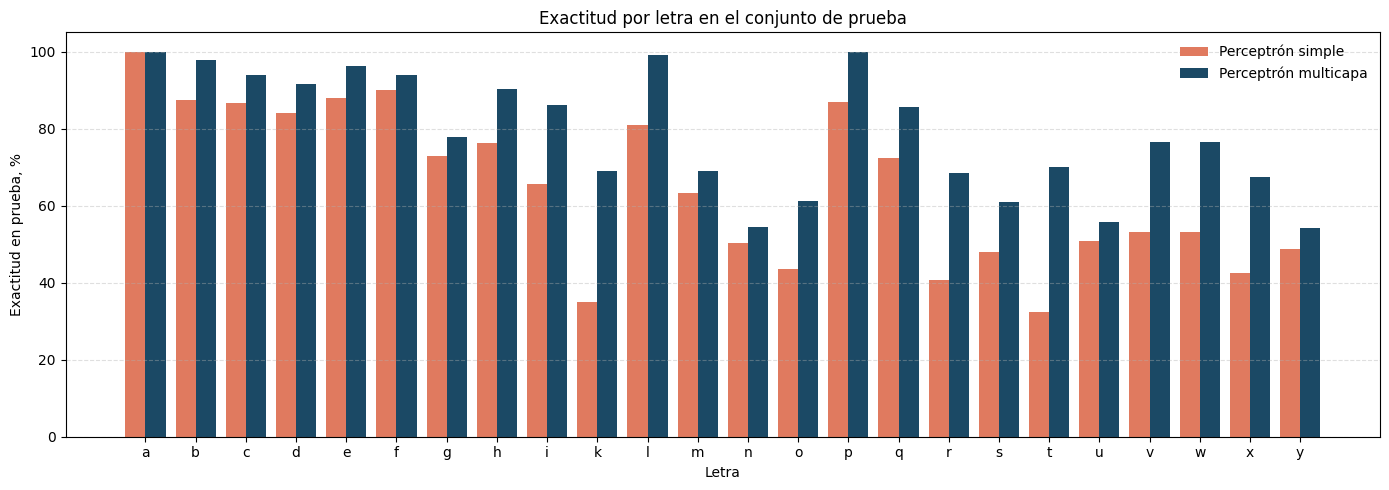

Letras con menor exactitud en el multicapa:
  y: 54.2% (168 imágenes de prueba)
  n: 54.4% (149 imágenes de prueba)
  u: 55.9% (136 imágenes de prueba)
  s: 61.0% (123 imágenes de prueba)
  o: 61.1% (108 imágenes de prueba)


In [ ]:
total_por_letra = np.bincount(y_test, minlength=n_clases)
acc_letra_mlp = np.array([np.mean(pred_test_mlp[y_test == k] == k) if total_por_letra[k] > 0 else np.nan for k in range(n_clases)])
acc_letra_per = np.array([np.mean(pred_test_per[y_test == k] == k) if total_por_letra[k] > 0 else np.nan for k in range(n_clases)])

x_pos = np.arange(n_clases)
plt.figure(figsize=(14, 5))
plt.bar(x_pos - 0.2, acc_letra_per * 100, width=0.4, color=color_per, label='Perceptrón simple')
plt.bar(x_pos + 0.2, acc_letra_mlp * 100, width=0.4, color=color_mlp, label='Perceptrón multicapa')
plt.xticks(x_pos, alphabet)
plt.xlabel('Letra')
plt.ylabel('Exactitud en prueba, %')
plt.title('Exactitud por letra en el conjunto de prueba')
plt.legend(frameon=False)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

peores = np.argsort(acc_letra_mlp)[:5]
print('Letras con menor exactitud en el multicapa:')
for k in peores:
  print(f'  {alphabet[k]}: {acc_letra_mlp[k] * 100:.1f}% ({total_por_letra[k]} imágenes de prueba)')

### **Letras que más se confunden**

De la matriz de confusión se toman las parejas (letra real, letra predicha) con más errores, sin contar los aciertos de la diagonal.

In [ ]:
errores = matriz.copy()
np.fill_diagonal(errores, 0)

pares = [(errores[i, j], i, j) for i in range(n_clases) for j in range(n_clases) if errores[i, j] > 0]
pares.sort(reverse=True)

tabla_confusiones = pd.DataFrame(
    [(alphabet[i], alphabet[j], n, n / total_por_letra[i] * 100) for n, i, j in pares[:8]],
    columns=['Letra real', 'Predicha como', 'Veces', '% de esa letra'])
tabla_confusiones.round(1)

,Letra real,Predicha como,Veces,% de esa letra
0,m,s,41,23.6
1,u,k,32,23.5
2,s,m,29,23.6
3,y,t,27,16.1
4,x,w,24,17.0
5,t,x,24,19.4
6,n,m,24,16.1
7,y,r,23,13.7


Imágenes mal clasificadas: 714 de 3586 (19.9%)


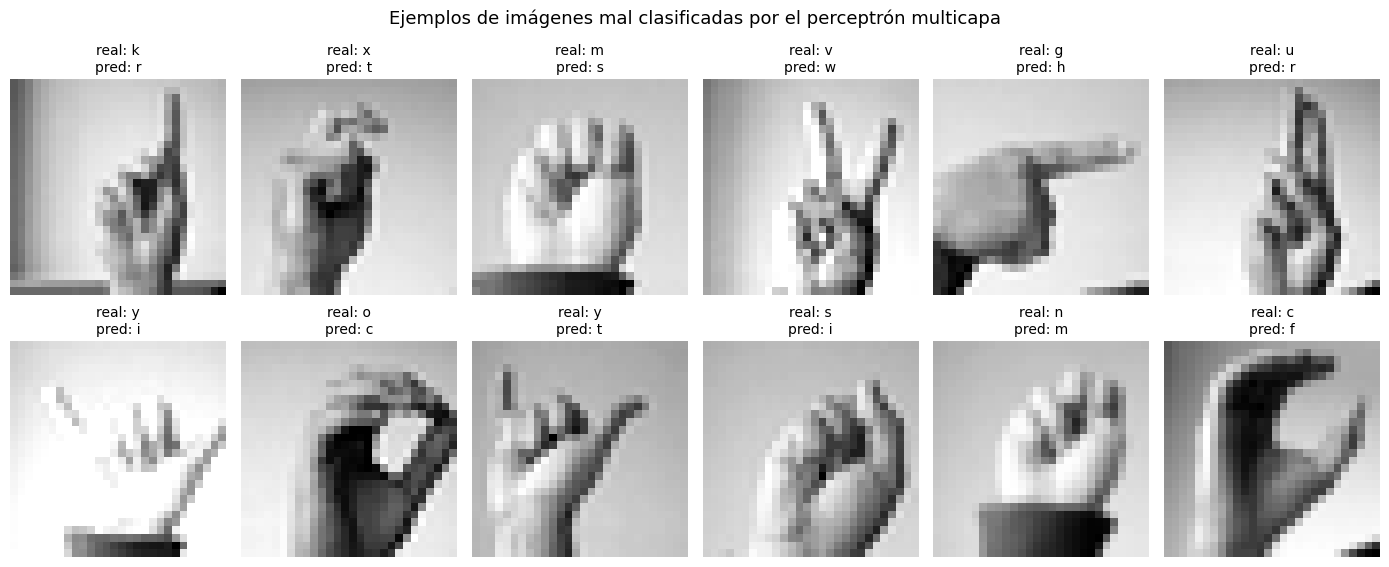

In [ ]:
# Galería de imágenes mal clasificadas por el perceptrón multicapa
idx_error = np.where(pred_test_mlp != y_test)[0]
print(f'Imágenes mal clasificadas: {len(idx_error)} de {len(y_test)} ({len(idx_error) / len(y_test) * 100:.1f}%)')

np.random.seed(7)
muestra = np.random.choice(idx_error, size=min(12, len(idx_error)), replace=False)

plt.figure(figsize=(14, 6))
for pos, i in enumerate(muestra):
  plt.subplot(2, 6, pos + 1)
  plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
  plt.title(f'real: {alphabet[y_test[i]]}\npred: {alphabet[pred_test_mlp[i]]}', fontsize=10)
  plt.axis('off')
plt.suptitle('Ejemplos de imágenes mal clasificadas por el perceptrón multicapa', fontsize=13)
plt.tight_layout()
plt.show()

Estas gráficas permiten comprobar si los errores se concentran en señas de forma parecida y si ocurren en imágenes con poca nitidez o con la mano en una posición distinta, que son los factores que se mencionaron antes.

## **Exploración de hiperparámetros**

La arquitectura y los hiperparámetros del perceptrón multicapa (dos capas ocultas de 256 y 128 neuronas, tasa de aprendizaje de 0.004) se justificaron con argumentos teóricos. Aquí se respaldan con un experimento: se entrena el modelo con distintas tasas de aprendizaje y distintas arquitecturas y se comparan **solo con el conjunto de validación**, de modo que el conjunto de prueba siga sin usarse para tomar decisiones.

Para que el experimento no tarde demasiado, cada configuración se entrena durante 10 épocas con las mismas semillas y el mismo tamaño de mini-batch (128).

In [ ]:
def entrenar_rapido(capas_ocultas, lr, epocas=10, mb=128, semilla=42):
  '''Entrena un perceptrón multicapa con las capas ocultas indicadas y devuelve la exactitud de validación por época.'''
  np.random.seed(semilla)
  tamanos = [784] + list(capas_ocultas) + [24]
  capas = []
  for i in range(len(tamanos) - 1):
    capas.append(Linear(tamanos[i], tamanos[i + 1]))
    if i < len(tamanos) - 2:
      capas.append(ReLU())
  red = Sequential_layers(capas)

  acc_epocas, costo_final = [], None
  for _ in range(epocas):
    costos = []
    for xb, yb in create_minibatches(mb, x_train, y_train):
      puntajes = red(xb.T.view(np_tensor))
      _, costo = softmaxXEntropy(puntajes, yb)
      costos.append(costo)
      red.backward()
      red.update(lr)
    costo_final = np.mean(costos)
    acc_epocas.append(accuracy(x_val, y_val, mb, red))
  return acc_epocas, costo_final, contar_parametros(red)

configuraciones = {
    'Base: 256-128, lr 0.004':   ((256, 128), 4e-3),
    'lr menor (0.001)':          ((256, 128), 1e-3),
    'lr mayor (0.01)':           ((256, 128), 1e-2),
    'Una capa oculta (128)':     ((128,), 4e-3),
    'Más pequeña (64-32)':       ((64, 32), 4e-3),
    'Más profunda (512-256-128)': ((512, 256, 128), 4e-3),
}

resultados_hp, curvas_hp = [], {}
for nombre_cfg, (capas_ocultas, lr) in configuraciones.items():
  acc_ep, costo_f, n_par = entrenar_rapido(capas_ocultas, lr)
  curvas_hp[nombre_cfg] = acc_ep
  resultados_hp.append({'Configuración': nombre_cfg, 'Parámetros': n_par, 'Costo final': costo_f,
                        'Acc. validación final': acc_ep[-1], 'Acc. validación máxima': max(acc_ep)})
  print(f'{nombre_cfg}: validación final {acc_ep[-1]:.4f}')

tabla_hp = pd.DataFrame(resultados_hp).set_index('Configuración')
tabla_hp.round(4)

Base: 256-128, lr 0.004: validación final 0.8073
lr menor (0.001): validación final 0.7780


/tmp/ipykernel_669/838280931.py:32: RuntimeWarning: overflow encountered in matmul
  Z = self.W @ X + self.b
/tmp/ipykernel_669/439739824.py:19: RuntimeWarning: invalid value encountered in subtract
  exp_scores = np.exp(x - x.max(axis=0, keepdims=True))   # Se resta el máximo de cada columna para evitar desbordamiento (no cambia el resultado)


lr mayor (0.01): validación final 0.0449
Una capa oculta (128): validación final 0.7875
Más pequeña (64-32): validación final 0.7621
Más profunda (512-256-128): validación final 0.8084


,Parámetros,Costo final,Acc. validación final,Acc. validación máxima
Configuración,,,,
"Base: 256-128, lr 0.004",236952,0.0004,0.8073061907417736,0.8073061907417736
lr menor (0.001),236952,0.0021,0.7780256553262688,0.7783045175683212
lr mayor (0.01),236952,NaN,0.0448968209704406,0.0448968209704406
Una capa oculta (128),103576,0.0011,0.7875069715560513,0.7877858337981037
Más pequeña (64-32),53112,0.0040,0.7621305075292806,0.7643614054657
Más profunda (512-256-128),569240,0.0001,0.8084216397099833,0.8084216397099833


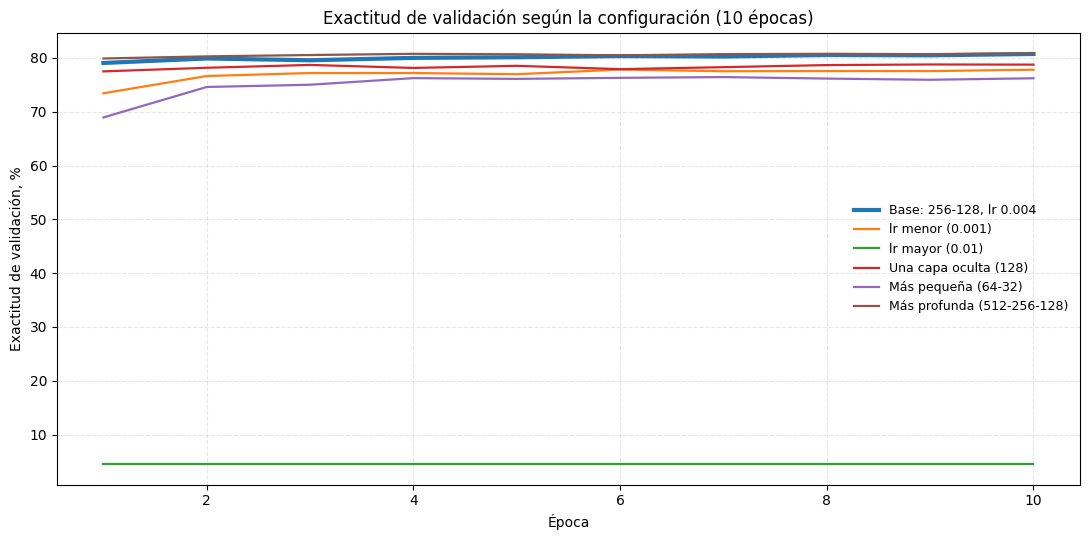

In [ ]:
plt.figure(figsize=(11, 5.5))
for nombre_cfg, acc_ep in curvas_hp.items():
  grueso = 3 if nombre_cfg.startswith('Base') else 1.6
  plt.plot(range(1, len(acc_ep) + 1), np.array(acc_ep) * 100, linewidth=grueso, label=nombre_cfg)
plt.xlabel('Época')
plt.ylabel('Exactitud de validación, %')
plt.title('Exactitud de validación según la configuración (10 épocas)')
plt.grid(alpha=0.3, linestyle='--')
plt.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
mejor_cfg = tabla_hp['Acc. validación final'].idxmax()
base_val = tabla_hp.loc['Base: 256-128, lr 0.004', 'Acc. validación final']
mejor_val = tabla_hp.loc[mejor_cfg, 'Acc. validación final']

display(Markdown(f"""
- **Mejor configuración en validación:** {mejor_cfg}, con {mejor_val * 100:.1f}% de exactitud de validación a las 10 épocas. La configuración base obtuvo {base_val * 100:.1f}%, una diferencia de {abs(mejor_val - base_val) * 100:.1f} puntos porcentuales.
- **Efecto de la tasa de aprendizaje:** con 0.001 la exactitud fue de {tabla_hp.loc['lr menor (0.001)', 'Acc. validación final'] * 100:.1f}%, con 0.004 de {base_val * 100:.1f}% y con 0.01 de {tabla_hp.loc['lr mayor (0.01)', 'Acc. validación final'] * 100:.1f}%.
- **Efecto de la arquitectura:** con una sola capa oculta se obtuvo {tabla_hp.loc['Una capa oculta (128)', 'Acc. validación final'] * 100:.1f}%, con la red más pequeña {tabla_hp.loc['Más pequeña (64-32)', 'Acc. validación final'] * 100:.1f}% y con la más profunda {tabla_hp.loc['Más profunda (512-256-128)', 'Acc. validación final'] * 100:.1f}%, frente a {base_val * 100:.1f}% de la base.
"""))


- **Mejor configuración en validación:** Más profunda (512-256-128), con 80.8% de exactitud de validación a las 10 épocas. La configuración base obtuvo 80.7%, una diferencia de 0.1 puntos porcentuales.
- **Efecto de la tasa de aprendizaje:** con 0.001 la exactitud fue de 77.8%, con 0.004 de 80.7% y con 0.01 de 4.5%.
- **Efecto de la arquitectura:** con una sola capa oculta se obtuvo 78.8%, con la red más pequeña 76.2% y con la más profunda 80.8%, frente a 80.7% de la base.


Una diferencia de menos de un punto porcentual entre configuraciones es del mismo orden que la variación que produce cambiar la semilla aleatoria, por lo que no basta para afirmar que una sea mejor que otra. Por eso la configuración base se conserva cuando ninguna otra la supera claramente, ya que es la más sencilla que alcanza ese nivel de exactitud.

_____________________________________________________________
#**Conclusiones**



_____________________________________________________________

- **Implementación de los modelos:** se construyeron en NumPy dos redes para clasificar 24 letras del alfabeto de lenguaje de señas a partir de imágenes de 28 por 28 pixeles. La primera es un perceptrón simple de una sola capa con salida softmax y la segunda es un perceptrón multicapa con dos capas ocultas. El proceso abarcó la carga y normalización de los datos, la división en conjuntos de entrenamiento, validación y prueba, la definición de las capas con sus funciones de avance y retroceso, y el entrenamiento por mini-batches.

- **Arquitecturas e hiperparámetros:** el perceptrón simple conecta los 784 valores de entrada directamente con las 24 clases y tiene 18,840 parámetros. El perceptrón multicapa tiene dos capas ocultas de 256 y 128 neuronas con activación ReLU y 236,952 parámetros, una cantidad cercana a 12.6 veces la del perceptrón simple. Ambos modelos se entrenaron durante 30 épocas con mini-batches de 128 imágenes, una tasa de aprendizaje de 0.004, la misma inicialización de He y la misma función de costo, de modo que la diferencia entre ellos corresponde a la arquitectura.

In [ ]:
razon_param = contar_parametros(model) / contar_parametros(perceptron)
dif_test = (acc_test_mlp - acc_test_per) * 100
mas_alto = 'multicapa' if acc_test_mlp >= acc_test_per else 'simple'
mejor_per = int(np.argmax(hist_per['acc_val']))
mejor_mlp = int(np.argmax(hist_mlp['acc_val']))

if acc_test_mlp >= acc_test_per:
  frase_capacidad = 'La diferencia en el conjunto de prueba a favor del perceptrón multicapa es consistente con esa mayor capacidad de representación.'
else:
  frase_capacidad = 'En esta ejecución el perceptrón simple igualó o superó al perceptrón multicapa en el conjunto de prueba, por lo que la mayor capacidad de representación no se tradujo en una exactitud más alta con estos hiperparámetros.'

texto = f"""
- **Desempeño comparado:** el perceptrón simple obtuvo una exactitud de {hist_per['acc_val'][-1] * 100:.1f}% en validación al terminar el entrenamiento y de {acc_test_per * 100:.1f}% en el conjunto de prueba. El perceptrón multicapa obtuvo {hist_mlp['acc_val'][-1] * 100:.1f}% en validación y {acc_test_mlp * 100:.1f}% en prueba. En el conjunto de prueba, el perceptrón {mas_alto} presentó la exactitud más alta, con una diferencia de {abs(dif_test):.1f} puntos porcentuales.

- **Comportamiento durante el entrenamiento:** el costo promedio de la última época fue {hist_per['costo'][-1]:.5f} para el perceptrón simple y {hist_mlp['costo'][-1]:.5f} para el perceptrón multicapa. La exactitud de validación del perceptrón simple alcanzó su valor máximo de {max(hist_per['acc_val']) * 100:.1f}% en la época {mejor_per}, mientras que la del perceptrón multicapa alcanzó su máximo de {max(hist_mlp['acc_val']) * 100:.1f}% en la época {mejor_mlp}.

- **Relación entre capacidad y exactitud:** el perceptrón simple construye únicamente fronteras de decisión lineales entre las clases en el espacio de pixeles, mientras que las capas ocultas con ReLU del perceptrón multicapa permiten fronteras no lineales. El perceptrón multicapa utiliza {razon_param:.1f} veces los parámetros del perceptrón simple. {frase_capacidad}
"""

display(Markdown(texto))


- **Desempeño comparado:** el perceptrón simple obtuvo una exactitud de 68.5% en validación al terminar el entrenamiento y de 66.6% en el conjunto de prueba. El perceptrón multicapa obtuvo 81.0% en validación y 80.1% en prueba. En el conjunto de prueba, el perceptrón multicapa presentó la exactitud más alta, con una diferencia de 13.5 puntos porcentuales.

- **Comportamiento durante el entrenamiento:** el costo promedio de la última época fue 0.00473 para el perceptrón simple y 0.00011 para el perceptrón multicapa. La exactitud de validación del perceptrón simple alcanzó su valor máximo de 69.5% en la época 5, mientras que la del perceptrón multicapa alcanzó su máximo de 81.1% en la época 28.

- **Relación entre capacidad y exactitud:** el perceptrón simple construye únicamente fronteras de decisión lineales entre las clases en el espacio de pixeles, mientras que las capas ocultas con ReLU del perceptrón multicapa permiten fronteras no lineales. El perceptrón multicapa utiliza 12.6 veces los parámetros del perceptrón simple. La diferencia en el conjunto de prueba a favor del perceptrón multicapa es consistente con esa mayor capacidad de representación.


In [ ]:
peor_letra = alphabet[int(np.nanargmin(acc_letra_mlp))]
par_top = pares[0] if pares else None
texto_ext = f"""
- **Análisis de errores:** el perceptrón multicapa clasificó mal {len(idx_error)} de {len(y_test)} imágenes de prueba. La letra con menor exactitud fue la {peor_letra} ({np.nanmin(acc_letra_mlp) * 100:.1f}%)"""
if par_top:
  texto_ext += f""" y la confusión más frecuente fue la letra {alphabet[par_top[1]]} predicha como {alphabet[par_top[2]]} ({par_top[0]} veces)."""
texto_ext += f"""

- **Justificación experimental de los hiperparámetros:** al comparar seis configuraciones en validación, la de mayor exactitud fue {mejor_cfg} ({mejor_val * 100:.1f}%), y la configuración base obtuvo {base_val * 100:.1f}%.
"""
display(Markdown(texto_ext))


- **Análisis de errores:** el perceptrón multicapa clasificó mal 714 de 3586 imágenes de prueba. La letra con menor exactitud fue la y (54.2%) y la confusión más frecuente fue la letra m predicha como s (41 veces).

- **Justificación experimental de los hiperparámetros:** al comparar seis configuraciones en validación, la de mayor exactitud fue Más profunda (512-256-128) (80.8%), y la configuración base obtuvo 80.7%.


- **Limitaciones identificadas:** ambos modelos clasifican de forma incorrecta una parte de las imágenes de prueba, con confusiones entre señas de forma parecida. Estos errores se relacionan con la baja resolución de las imágenes, con la variación en la posición de la mano, el fondo y la iluminación, y con el hecho de que una red completamente conectada procesa cada pixel de manera independiente sin considerar a sus vecinos.

- **Posibles líneas de mejora:** el desempeño podría explorarse con arquitecturas que aprovechen la estructura espacial de las imágenes, como las redes convolucionales, y con técnicas de aumento de datos que incluyan pequeños giros y desplazamientos de las imágenes de entrenamiento. También se podría evaluar un número menor de épocas a partir de la época con mayor exactitud de validación, y repetir cada configuración con distintas semillas aleatorias, ya que los pesos iniciales producen variaciones entre corridas.

------------------------------------------------------
# **Referencias bibliográficas**

Google for Developers. (s. f.). *Linear regression: Hyperparameters*. https://developers.google.com/machine-learning/crash-course/linear-regression/hyperparameters#learning_rate

Google for Developers. (s. f.). *Redes neuronales: Funciones de activación*. https://developers.google.com/machine-learning/crash-course/neural-networks/activation-functions?hl=es-419

Pepe Cantoral, Ph.D. (2021, 19 de febrero). *Gradient Descent – REDES NEURONALES - (Parte 5)* [Video]. YouTube. https://www.youtube.com/watch?v=lnDjwepC-5I

Pepe Cantoral, Ph.D. (2021, 22 de febrero). *¿Por qué usamos el gradiente para entrenar Redes Neuronales? Ejemplo - Deep Learning - (Parte 6)* [Video]. YouTube. https://www.youtube.com/watch?v=Cr5cYDrMYZQ

Pepe Cantoral, Ph.D. (2021, 10 de marzo). *"Backpropagation" – Fundamentos de Deep Learning – (Parte 7)* [Video]. YouTube. https://www.youtube.com/watch?v=4nDsiV3GXa8

Pepe Cantoral, Ph.D. (2021, 15 de mayo). *¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING!* [Video]. YouTube. https://youtu.be/_shpKyA89QQ

Pepe Cantoral, Ph.D. (2021, 18 de mayo). *¡Red Neuronal Desde Cero estilo FRAMEWORK de DEEP LEARNING - Parte 2!* [Video]. YouTube. https://youtu.be/l2v2mVcOx6o

Pepe Cantoral, Ph.D. (2021, 6 de julio). *¡Red Neuronal usando PyTorch! PyTorch tutorial* [Video]. YouTube. https://youtu.be/qQELiV1_GHA

Raschka, S., Liu, Y., Mirjalili, V., & Dzhulgakov, D. (2022). *Machine learning with PyTorch and Scikit-Learn: Develop machine learning and deep learning models with Python*. Packt Publishing.

-------------------------------------------------------